# Tensores de inércia das peças — blocos para o notebook
Bloco 1: imports · 2: funções gerais · 3: braço (junta 150°) · 4: perna · 5: ombro (manivela) · 6: motor · 7: bateria · 8: quadril · 9: robô completo (montagem) · 10: corpos móveis e manivela a 30 rpm · 11: modelo dinâmico (Newton-Euler) e marcha na corda

In [1]:
# ===================== BLOCO 1 — IMPORTS =====================
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Arc
from IPython.display import display, Math

sp.init_printing(use_latex='mathjax')

In [2]:
# ===================== BLOCO 2 — FUNÇÕES GERAIS =====================
# Convenção: SI (kg, m). Sistema de cada peça com origem no CM; "corpo" = sistema comum onde as peças são compostas.

# ---------- exibição ----------
def eq(*partes):
    """Mostra uma cadeia de igualdades em LaTeX. Partes iniciadas por '@' entram sem '=' (unidade ou observação).
    Ex.: eq('m_1', expressao, valor, '@\\mathrm{g}')"""
    tex = ''
    for i, p in enumerate(partes):
        txt = p if isinstance(p, str) else sp.latex(p)
        if txt.startswith('@'):
            tex += r'\;' + txt[1:]
        else:
            tex += (' = ' if i else '') + txt
    display(Math(tex))

def em_g_mm2(I):
    """kg·m² → g·mm² (fator 1e9), com 5 algarismos significativos."""
    return (I*10**9).applyfunc(lambda x: sp.N(x, 5))

# ---------- tensores de inércia de sólidos maciços (no CM, eixos principais) ----------
def I_paralelepipedo(m, a, b, c):
    """Arestas a, b, c ao longo de x, y, z da peça."""
    return sp.diag(m*(b**2 + c**2)/12, m*(a**2 + c**2)/12, m*(a**2 + b**2)/12)

def I_cilindro(m, r, h):
    """Eixo do cilindro ao longo de z."""
    return sp.diag(m*(3*r**2 + h**2)/12, m*(3*r**2 + h**2)/12, m*r**2/2)

def I_esfera(m, r):
    return sp.Rational(2, 5)*m*r**2*sp.eye(3)

# ---------- transformações ----------
def Rz(a):
    """Rotação de ângulo a em torno de z (sentido anti-horário)."""
    return sp.Matrix([[sp.cos(a), -sp.sin(a), 0], [sp.sin(a), sp.cos(a), 0], [0, 0, 1]])

def girar_tensor(I, R):
    """Escreve o tensor no sistema do corpo: R·I·Rᵀ  (R: sistema da peça → corpo)."""
    return R*I*R.T

def steiner(I_cm, m, d):
    """Eixos paralelos (forma tensorial): I = I_cm + m(|d|²·1 − d dᵀ); d = posição do CM da peça relativa ao ponto de referência."""
    d = sp.Matrix(d)
    return I_cm + m*(d.dot(d)*sp.eye(3) - d*d.T)

def compor(pecas):
    """pecas: lista de dicts {m, r (CM da peça no corpo), I (tensor da peça no CM, já no sistema do corpo)}.
    Retorna massa total, CM do conjunto e tensor de inércia do conjunto em torno do CM do conjunto."""
    M = sum(p['m'] for p in pecas)
    rcm = sum((p['m']*sp.Matrix(p['r']) for p in pecas), sp.zeros(3, 1))/M
    I = sum((steiner(p['I'], p['m'], sp.Matrix(p['r']) - rcm) for p in pecas), sp.zeros(3, 3))
    return M, rcm, I

# ---------- barras finas no plano xy (palitos) ----------
def barra(m, L, alpha, inicio, t, w):
    """Barra de comprimento L, direção u=(sin α, cos α) medida a partir de +y, espessura t (no plano), largura w (eixo z)."""
    inicio = sp.Matrix(inicio)
    u = sp.Matrix([sp.sin(alpha), sp.cos(alpha), 0])
    I_loc = I_paralelepipedo(m, t, L, w)                     # x: espessura, y: ao longo da barra, z: largura
    return dict(m=m, L=L, alpha=alpha, ini=inicio, fim=inicio + u*L, r=inicio + u*L/2,
                I=girar_tensor(I_loc, Rz(-alpha)), I_loc=I_loc)

def cadeia_de_barras(Ls, alphas, m_total, t, w, inicio=(0, 0, 0)):
    """Barras encadeadas (fim de uma = início da próxima); massa de cada uma ∝ comprimento (mesma seção e material)."""
    Ltot = sum(Ls); pecas, ini = [], sp.Matrix(inicio)
    for L, a in zip(Ls, alphas):
        p = barra(m_total*L/Ltot, L, a, ini, t, w)
        pecas.append(p); ini = p['fim']
    return pecas

1) Massa de cada segmento (seção e material iguais → massa ∝ comprimento)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Momentos principais [g·mm²]: [93.94, 3342.97, 3408.7]


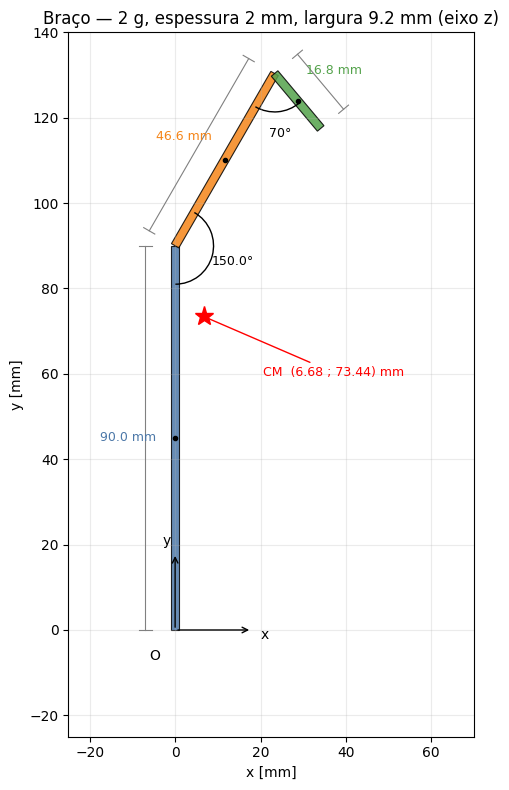

In [3]:
# ===================== BLOCO 3 — BRAÇO =====================
# ---------- dados medidos ----------
mm = sp.Rational(1, 1000)
L1, L2, L3 = 90*mm, sp.Rational(466, 10)*mm, sp.Rational(168, 10)*mm   # segmento longo, inclinado, gancho
w, t = sp.Rational(92, 10)*mm, 2*mm                                    # largura (eixo z) e espessura (no plano)
m_braco = sp.Rational(2, 1000)                                          # 2 g
ang_junta, ang_gancho = sp.rad(150), sp.rad(70)             # ângulos INTERNOS: junta medida na foto do braço (≈ 140,8°, desvio de 39,2°);
                                                                      # os 130° medidos antes davam 50° de desvio, bem mais aberto que a foto. Gancho: 70°

# direções a partir de +y (u = (sin α, cos α))
alpha1 = 0
alpha2 = sp.pi - ang_junta                    # β = 50°
alpha3 = alpha2 + (sp.pi - ang_gancho)        # γ = 160°

pecas = cadeia_de_barras([L1, L2, L3], [alpha1, alpha2, alpha3], m_braco, t, w)
M, rcm, I = compor(pecas)

# ---------- equações (simbólicas → numéricas) ----------
mi, Li, ti, wi, mb, Lt = sp.symbols('m_i L_i t w m_{braco} L_{tot}')
print('1) Massa de cada segmento (seção e material iguais → massa ∝ comprimento)')
eq('m_i', mb*Li/Lt)
for k, p in enumerate(pecas, 1):
    eq(f'm_{k}', sp.N(p['m']*1000, 4), r'@\mathrm{g}')

print('\n2) Tensor de cada segmento no próprio CM (paralelepípedo, eixo y ao longo do segmento)')
eq(r'I^*_i', I_paralelepipedo(mi, ti, Li, wi))

print('\n3) Posição do CM e tensor de cada segmento no sistema do braço')
eq(r'\mathbf{r}_i', r'\mathbf{r}_{ini,i} + \tfrac{L_i}{2}\,\mathbf{u}_i', r'@\text{com }\mathbf{u}_i=(\sin\alpha_i,\cos\alpha_i,0)')
eq(r'I_i', r'R_z(-\alpha_i)\,I^*_i\,R_z(-\alpha_i)^{T}')
for k, p in enumerate(pecas, 1):
    eq(f'\\alpha_{k}', sp.N(sp.deg(p['alpha']), 4), r'@^\circ')
    eq(f'\\mathbf{{r}}_{k}\\,[\\mathrm{{mm}}]', (p['r']*1000).applyfunc(lambda x: sp.N(x, 5)))

print('\n4) Composição do braço')
eq('M', r'\sum_i m_i', sp.N(M*1000, 4), r'@\mathrm{g}')
eq(r'\mathbf{r}_{CM}', r'\frac{1}{M}\sum_i m_i\,\mathbf{r}_i', (rcm*1000).applyfunc(lambda x: sp.N(x, 5)), r'@\mathrm{mm}')
eq(r'I^*_{braco}', r'\sum_i \left[ I_i + m_i\left(|\mathbf{d}_i|^2\,\mathbb{1} - \mathbf{d}_i\mathbf{d}_i^{T}\right)\right]', r'@\text{com }\mathbf{d}_i=\mathbf{r}_i-\mathbf{r}_{CM}')
eq(r'I^*_{braco}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I))
eq(r'I^*_{braco}\,[\mathrm{kg\cdot m^2}]', I.applyfunc(lambda x: sp.N(x, 5)))

# momentos principais (autovalores) — checagem
princ = sorted(float(sp.re(v))*1e9 for v in I.eigenvals())
print('\nMomentos principais [g·mm²]:', [round(v, 2) for v in princ])

# ---------- desenho do braço (plano xy, mm, escala real) ----------
def arr(v): return np.array([float(x) for x in v[:2]])*1000
cores = ['#4C78A8', '#F58518', '#54A24B']
fig, ax = plt.subplots(figsize=(5.2, 8))
h = float(t)*1000/2
for k, p in enumerate(pecas):
    ini, fim = arr(p['ini']), arr(p['fim'])
    u = (fim - ini)/np.linalg.norm(fim - ini); n = np.array([-u[1], u[0]])
    ax.add_patch(Polygon([ini + h*n, fim + h*n, fim - h*n, ini - h*n], closed=True, fc=cores[k], ec='k', lw=.8, alpha=.85))
    # cota paralela ao segmento
    off = 7*n if k != 2 else 7*n
    ax.plot(*zip(ini + off, fim + off), color='gray', lw=.8)
    for e in (ini, fim): ax.plot(*zip(e + off - 1.5*n, e + off + 1.5*n), color='gray', lw=.8)
    ax.text(*((ini + fim)/2 + 11*n), f'{float(p["L"])*1000:.1f} mm', ha='center', va='center', fontsize=9, color=cores[k], rotation=0)
    ax.plot(*arr(p['r']), 'o', color='k', ms=3)                       # CM de cada segmento

# ângulos internos
j1 = arr(pecas[0]['fim']); j2 = arr(pecas[1]['fim'])
a_junta  = (-90, float(sp.deg(sp.pi/2 - alpha2)))
a_gancho = (float(sp.deg(sp.pi/2 - alpha2)) + 180 - 360, float(sp.deg(sp.pi/2 - alpha3)))
for c, (t1, t2), txt in ((j1, a_junta, f'{float(sp.deg(ang_junta)):.1f}°'), (j2, a_gancho, f'{float(sp.deg(ang_gancho)):.0f}°')):
    ax.add_patch(Arc(c, 18, 18, theta1=t1, theta2=t2, color='k', lw=1))
    mid = np.deg2rad((t1 + t2)/2)
    ax.text(c[0] + 14*np.cos(mid), c[1] + 14*np.sin(mid), txt, fontsize=9, ha='center', va='center')

# eixos do braço e CM do conjunto
ax.annotate('', xy=(18, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k'))
ax.annotate('', xy=(0, 18), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k'))
ax.text(20, -2, 'x', fontsize=10); ax.text(-3, 20, 'y', fontsize=10); ax.text(-6, -7, 'O')
cx, cy = (float(v)*1000 for v in rcm[:2])
ax.plot(cx, cy, 'r*', ms=14, zorder=5)
ax.annotate(f'CM  ({cx:.2f} ; {cy:.2f}) mm', (cx, cy), xytext=(cx + 14, cy - 14), color='r', fontsize=9,
            arrowprops=dict(arrowstyle='-', color='r'))
ax.set_aspect('equal'); ax.set_xlim(-25, 70); ax.set_ylim(-25, 140); ax.grid(alpha=.25)
ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]')
ax.set_title(f'Braço — {float(m_braco)*1000:.0f} g, espessura {float(t)*1000:.0f} mm, largura {float(w)*1000:.1f} mm (eixo z)')
plt.tight_layout(); plt.show()

1) Massa de cada peça (mesma seção e material → massa ∝ comprimento)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Momentos principais [g·mm²]: [48.42, 1176.6, 1220.21]


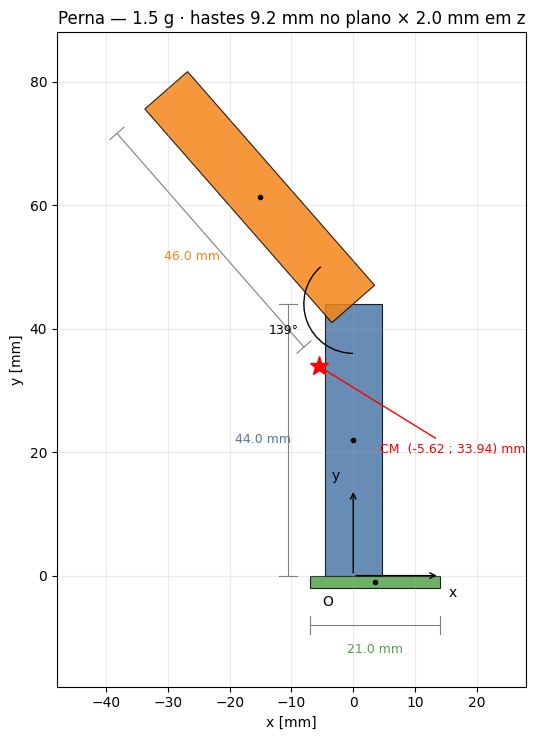

In [4]:
# ===================== BLOCO 4 — PERNA (contrapeso) =====================
# ---------- função de desenho (reaproveitável; pode ir para o bloco 2) ----------
def desenhar_conjunto(pecas, rcm, espessuras, cores, titulo, angulos=(), lados=None, xlim=(-40, 40), ylim=(-15, 70), figsize=(6, 7)):
    """pecas: dicts de barra(); espessuras: espessura NO PLANO de cada peça [m] (só para o desenho);
    angulos: [(centro_mm, th1, th2, texto)] (arco anti-horário de th1 a th2); lados: +1/-1 por peça = lado da cota."""
    arr = lambda v: np.array([float(x) for x in v[:2]])*1000
    fig, ax = plt.subplots(figsize=figsize)
    lados = lados or [1]*len(pecas)
    for p, e, cor, lado in zip(pecas, espessuras, cores, lados):
        ini, fim = arr(p['ini']), arr(p['fim'])
        u = (fim - ini)/np.linalg.norm(fim - ini); n = lado*np.array([-u[1], u[0]]); h = float(e)*1000/2
        ax.add_patch(Polygon([ini + h*n, fim + h*n, fim - h*n, ini - h*n], closed=True, fc=cor, ec='k', lw=.8, alpha=.85))
        off = (h + 6)*n                                                  # cota paralela à peça
        ax.plot(*zip(ini + off, fim + off), color='gray', lw=.8)
        for pt in (ini, fim): ax.plot(*zip(pt + off - 1.5*n, pt + off + 1.5*n), color='gray', lw=.8)
        ax.text(*((ini + fim)/2 + (h + 10)*n), f'{float(p["L"])*1000:.1f} mm', ha='center', va='center', fontsize=9, color=cor)
        ax.plot(*arr(p['r']), 'o', color='k', ms=3)                      # CM de cada peça
    for c, th1, th2, txt in angulos:
        ax.add_patch(Arc(c, 16, 16, theta1=th1, theta2=th2, color='k', lw=1))
        mid = np.deg2rad((th1 + th2)/2); ax.text(c[0] + 12*np.cos(mid), c[1] + 12*np.sin(mid), txt, fontsize=9, ha='center', va='center')
    ax.annotate('', xy=(14, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k'))
    ax.annotate('', xy=(0, 14), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k'))
    ax.text(15.5, -3.5, 'x'); ax.text(-3.5, 15.5, 'y'); ax.text(-5, -5, 'O')
    cx, cy = (float(v)*1000 for v in rcm[:2])
    ax.plot(cx, cy, 'r*', ms=14, zorder=5)
    ax.annotate(f'CM  ({cx:.2f} ; {cy:.2f}) mm', (cx, cy), xytext=(cx + 10, cy - 14), color='r', fontsize=9, arrowprops=dict(arrowstyle='-', color='r'))
    ax.set_aspect('equal'); ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.grid(alpha=.25)
    ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_title(titulo)
    plt.tight_layout(); plt.show()

# ---------- dados medidos ----------
mm = sp.Rational(1, 1000)
Lc, Lb, Lp = 44*mm, 46*mm, 21*mm                       # haste inferior (com o pé) · haste superior inclinada · pé
esp, larg = 2*mm, sp.Rational(92, 10)*mm               # mesmo palito: espessura 2 mm, largura 9,2 mm
m_perna = sp.Rational(15, 10)/1000                     # 1,5 g
ang_joelho = sp.rad(sp.Rational(1388, 10))              # ÂNGULO INTERNO entre as hastes: medido na foto da perna por ajuste de retas (≈ 138,8°)
d_calc = 7*mm                                          # calcanhar: do eixo da haste até a ponta traseira do pé (foto: ≈ 7 mm; o dedão fica ≈ 14 mm à frente do eixo)

# Hipótese de orientação (CONFIRMAR): na foto as hastes estão deitadas → face larga (9,2 mm) NO plano da dobra, 2 mm fora dele.
# O pé é um pedaço de palito em pé: 21 mm × 2 mm no plano, 9,2 mm fora do plano (foto lateral).
largura_no_plano = True
t_h, w_h = (larg, esp) if largura_no_plano else (esp, larg)    # (extensão no plano, extensão em z) das hastes
t_p, w_p = esp, larg                                           # pé

# ---------- geometria (origem O: extremo inferior da haste de 44 mm; y ao longo dela) ----------
Ltot = Lc + Lb + Lp
alpha_c = 0
alpha_b = -(sp.pi - ang_joelho)                         # haste superior inclinada para a esquerda (u = (sin α, cos α))
haste_inf = barra(m_perna*Lc/Ltot, Lc, alpha_c, (0, 0, 0), t_h, w_h)
haste_sup = barra(m_perna*Lb/Ltot, Lb, alpha_b, haste_inf['fim'], t_h, w_h)
pe        = barra(m_perna*Lp/Ltot, Lp, sp.pi/2, (-d_calc, -esp/2, 0), t_p, w_p)   # pé com calcanhar: 7 mm atrás do eixo da haste, 14 mm à frente (dedão)
pecas_perna = [haste_inf, haste_sup, pe]
M_perna, rcm_perna, I_perna = compor(pecas_perna)

# ---------- equações (simbólicas → numéricas) ----------
mi, Li, ti, wi, mp, Lt = sp.symbols('m_i L_i t_i w_i m_{perna} L_{tot}')
print('1) Massa de cada peça (mesma seção e material → massa ∝ comprimento)')
eq('m_i', mp*Li/Lt)
for nome, p in zip(('haste inferior', 'haste superior', 'pé'), pecas_perna):
    eq(r'm_{\text{' + nome + '}}', sp.N(p['m']*1000, 4), r'@\mathrm{g}')

print('\n2) Tensor de cada peça no próprio CM (t_i: extensão no plano xy · w_i: extensão em z)')
eq(r'I^*_i', I_paralelepipedo(mi, ti, Li, wi))

print('\n3) CM de cada peça no sistema da perna e direção')
for nome, p in zip(('haste inferior', 'haste superior', 'pé'), pecas_perna):
    eq(r'\alpha_{\text{' + nome + '}}', sp.N(sp.deg(p['alpha']), 4), r'@^\circ')
    eq(r'\mathbf{r}_{\text{' + nome + r'}}\,[\mathrm{mm}]', (p['r']*1000).applyfunc(lambda x: sp.N(x, 5)))

print('\n4) Composição da perna')
eq('M', r'\sum_i m_i', sp.N(M_perna*1000, 4), r'@\mathrm{g}')
eq(r'\mathbf{r}_{CM}', r'\frac{1}{M}\sum_i m_i\,\mathbf{r}_i', (rcm_perna*1000).applyfunc(lambda x: sp.N(x, 5)), r'@\mathrm{mm}')
eq(r'I^*_{perna}', r'\sum_i \left[ I_i + m_i\left(|\mathbf{d}_i|^2\,\mathbb{1} - \mathbf{d}_i\mathbf{d}_i^{T}\right)\right]', r'@\text{com }\mathbf{d}_i=\mathbf{r}_i-\mathbf{r}_{CM}')
eq(r'I^*_{perna}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_perna))
eq(r'I^*_{perna}\,[\mathrm{kg\cdot m^2}]', I_perna.applyfunc(lambda x: sp.N(x, 5)))
print('\nMomentos principais [g·mm²]:', [round(v, 2) for v in sorted(float(sp.re(v))*1e9 for v in I_perna.eigenvals())])

# ---------- desenho (escala real, mm) ----------
j = np.array([float(x) for x in haste_inf['fim'][:2]])*1000
ang_j = (float(sp.deg(sp.pi/2 - alpha_b)), 270)                 # arco interno: da haste superior até a haste inferior (para baixo)
desenhar_conjunto(pecas_perna, rcm_perna, [t_h, t_h, t_p], ['#4C78A8', '#F58518', '#54A24B'],
                  f'Perna — {float(m_perna)*1000:.1f} g · hastes {float(t_h)*1000:.1f} mm no plano × {float(w_h)*1000:.1f} mm em z',
                  angulos=[(j, *ang_j, f'{float(sp.deg(ang_joelho)):.0f}°')], lados=[1, 1, -1],
                  xlim=(-48, 28), ylim=(-18, 88), figsize=(6, 7.5))

1) Massa de cada peça (mesma densidade → massa ∝ volume; o furo tem volume negativo)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

...

<IPython.core.display.Math object>


5) Em torno do eixo do motor (ponto O): I_O = I* + M(|r_CM|²·1 − r_CM r_CMᵀ)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Momentos principais no CM [g·mm²]: [21.976, 56.686, 68.867]


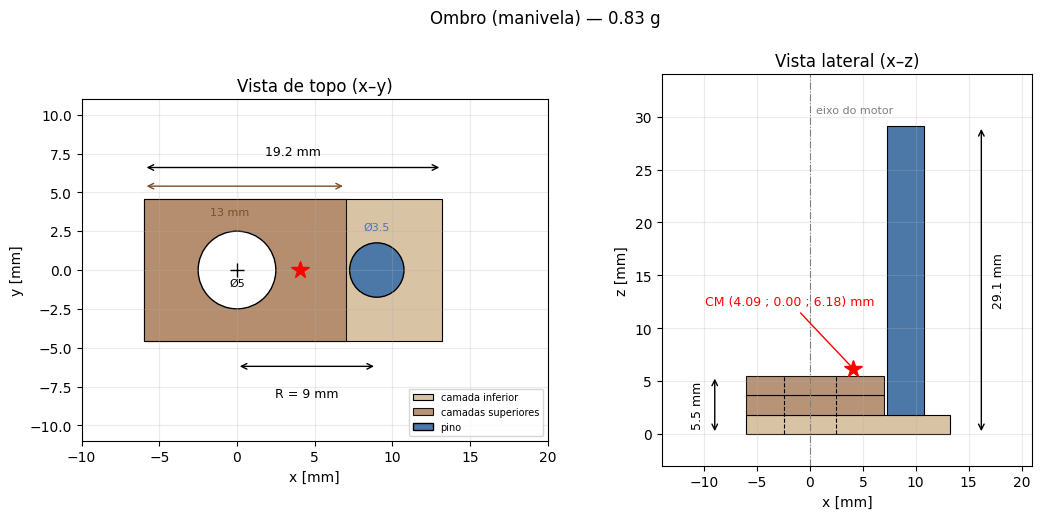

In [5]:
# ===================== BLOCO 5 — OMBRO (manivela acoplada ao motor) =====================
# Sistema da manivela: origem O no eixo do furo (eixo do motor), na face inferior da base; z ao longo do eixo (paralelo ao pino);
# x do furo em direção ao pino; y na largura. Peça = 3 camadas de palito coladas + pino cilíndrico, com furo passante.

# ---------- dados medidos (fotos) ----------
mm = sp.Rational(1, 1000)
L_base, L_topo = sp.Rational(192, 10)*mm, 13*mm             # camada inferior (19,2) · duas camadas superiores (13)
h_blk, n_cam   = sp.Rational(55, 10)*mm, 3                  # altura total da pilha · nº de camadas
e_cam          = h_blk/n_cam                                # espessura de cada camada (≈ 1,83 mm)
w_blk          = sp.Rational(92, 10)*mm                     # largura = largura do palito (CONFIRMAR)
d_furo         = 5*mm                                       # furo passante (eixo do motor)
R_man          = 9*mm                                       # raio da manivela: eixo do furo → eixo do pino
d_pino         = sp.Rational(35, 10)*mm                     # diâmetro do pino (foto de topo)
H_tot          = sp.Rational(291, 10)*mm                    # topo do pino → face inferior da base
L_pino         = H_tot - e_cam                              # pino apoiado sobre a camada inferior (ASSUMIDO)
x_esq          = -6*mm                                      # extremo esquerdo da base em relação ao furo (ESTIMADO das fotos)
m_ombro        = sp.Rational(83, 100)/1000                  # 0,83 g  ← CONFIRMAR (o valor enviado foi "83 g")

# ---------- peças: (nome, volume, CM, tensor unitário-de-massa a ser escalado) ----------
x1, x2 = x_esq, x_esq + L_base                              # camada inferior
x3     = x_esq + L_topo                                     # fim das camadas superiores
geo = [   # nome, centro, dimensões / forma
    ('camada 1 (inf.)',   (  (x1 + x2)/2, 0, e_cam/2),                'cx', (L_base, w_blk, e_cam)),
    ('camada 2',          (  (x_esq + x3)/2, 0, 3*e_cam/2),           'cx', (L_topo, w_blk, e_cam)),
    ('camada 3',          (  (x_esq + x3)/2, 0, 5*e_cam/2),           'cx', (L_topo, w_blk, e_cam)),
    ('pino',              (  R_man, 0, e_cam + L_pino/2),             'cl', (d_pino/2, L_pino)),
    ('furo (massa negativa)', (0, 0, h_blk/2),                        'cl', (d_furo/2, h_blk)),
]
vol = lambda forma, dim: dim[0]*dim[1]*dim[2] if forma == 'cx' else sp.pi*dim[0]**2*dim[1]
V = [(-1 if 'furo' in n else 1)*vol(f, d) for n, c, f, d in geo]       # volumes com sinal (o furo remove material)
V_liq = sum(V)

pecas_omb = []
for (nome, c, forma, dim), v in zip(geo, V):
    m = m_ombro*v/V_liq                                                # mesma densidade em tudo (ASSUMIDO)
    I_loc = I_paralelepipedo(abs(m), *dim) if forma == 'cx' else I_cilindro(abs(m), *dim)
    pecas_omb.append(dict(nome=nome, m=m, r=sp.Matrix(c), I=sp.sign(m)*I_loc, V=v))

M_omb, rcm_omb, I_omb = compor(pecas_omb)                              # tensor no CM da manivela
I_eixo_pt = steiner(I_omb, M_omb, rcm_omb)                             # tensor no ponto O (sobre o eixo do motor)
J_eixo = I_eixo_pt[2, 2]                                               # momento de inércia em torno do eixo do motor

# ---------- equações (simbólicas → numéricas) ----------
mi, Vi, Vl, mo, a_, b_, c_, r_, h_ = sp.symbols('m_i V_i V_{liq} m_{ombro} a b c r h')
print('1) Massa de cada peça (mesma densidade → massa ∝ volume; o furo tem volume negativo)')
eq('m_i', mo*Vi/Vl, r'@V_{liq}=\sum_i V_i')
for p in pecas_omb:
    eq(r'V_{\text{' + p['nome'] + '}}', sp.N(p['V']*10**9, 4), r'@\mathrm{mm^3}', r'@\;\Rightarrow\; m =' + sp.latex(sp.N(p['m']*1000, 3)) + r'\,\mathrm{g}')

print('\n2) Tensores no CM de cada peça (x,y,z da peça; cilindro com eixo em z)')
eq(r'I^*_{\text{paralelepípedo}}', I_paralelepipedo(mi, a_, b_, c_))
eq(r'I^*_{\text{cilindro}}', I_cilindro(mi, r_, h_))

print('\n3) CM de cada peça no sistema da manivela [mm]')
for p in pecas_omb:
    eq(r'\mathbf{r}_{\text{' + p['nome'] + '}}', (p['r']*1000).applyfunc(lambda x: sp.N(x, 4)))

print('\n4) Composição')
eq('M', r'\sum_i m_i', sp.N(M_omb*1000, 4), r'@\mathrm{g}')
eq(r'\mathbf{r}_{CM}', r'\frac{1}{M}\sum_i m_i\,\mathbf{r}_i', (rcm_omb*1000).applyfunc(lambda x: sp.N(x, 4)), r'@\mathrm{mm}')
eq(r'I^*_{ombro}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_omb))
eq(r'I^*_{ombro}\,[\mathrm{kg\cdot m^2}]', I_omb.applyfunc(lambda x: sp.N(x, 5)))
print('\n5) Em torno do eixo do motor (ponto O): I_O = I* + M(|r_CM|²·1 − r_CM r_CMᵀ)')
eq(r'I_O\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_eixo_pt))
eq(r'J_{eixo}=(I_O)_{zz}', sp.N(J_eixo*10**9, 5), r'@\mathrm{g\cdot mm^2}', sp.N(J_eixo, 5), r'@\mathrm{kg\cdot m^2}')
print('Momentos principais no CM [g·mm²]:', [round(v, 3) for v in sorted(float(sp.re(v))*1e9 for v in I_omb.eigenvals())])

# ---------- desenho: vista de topo (x–y) e vista lateral (x–z), escala real em mm ----------
f = lambda v: float(v)*1000
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw=dict(width_ratios=[1, 1]))
cb, cp, cs = '#D8C3A5', '#B08968', '#4C78A8'
for ax in (ax1, ax2): ax.set_aspect('equal'); ax.grid(alpha=.25); ax.set_xlabel('x [mm]')
cx, cy, cz = (f(v) for v in rcm_omb)
# topo
ax1.add_patch(plt.Rectangle((f(x1), -f(w_blk)/2), f(L_base), f(w_blk), fc=cb, ec='k', lw=.8, label='camada inferior'))
ax1.add_patch(plt.Rectangle((f(x_esq), -f(w_blk)/2), f(L_topo), f(w_blk), fc=cp, ec='k', lw=.8, alpha=.9, label='camadas superiores'))
ax1.add_patch(plt.Circle((0, 0), f(d_furo)/2, fc='white', ec='k', lw=1))
ax1.add_patch(plt.Circle((f(R_man), 0), f(d_pino)/2, fc=cs, ec='k', lw=1, label='pino'))
ax1.annotate('', xy=(f(R_man), -6.2), xytext=(0, -6.2), arrowprops=dict(arrowstyle='<->'))
ax1.text(f(R_man)/2, -8.2, f'R = {f(R_man):.0f} mm', ha='center', fontsize=9)
ax1.annotate('', xy=(f(x2), 6.6), xytext=(f(x1), 6.6), arrowprops=dict(arrowstyle='<->'))
ax1.text((f(x1) + f(x2))/2, 7.4, f'{f(L_base):.1f} mm', ha='center', fontsize=9)
ax1.annotate('', xy=(f(x3), 5.4), xytext=(f(x_esq), 5.4), arrowprops=dict(arrowstyle='<->', color='#7a4f2a'))
ax1.text((f(x_esq) + f(x3))/2 - 1, 3.5, f'{f(L_topo):.0f} mm', ha='center', fontsize=8, color='#7a4f2a')
ax1.text(0, -1.0, f'Ø{f(d_furo):.0f}', ha='center', fontsize=8); ax1.text(f(R_man), 2.6, f'Ø{f(d_pino):.1f}', ha='center', fontsize=8, color=cs)
ax1.plot(cx, cy, 'r*', ms=13, zorder=5); ax1.plot(0, 0, 'k+', ms=10)
ax1.set_ylim(-11, 11); ax1.set_xlim(-10, 20); ax1.set_ylabel('y [mm]'); ax1.set_title('Vista de topo (x–y)'); ax1.legend(fontsize=7, loc='lower right')
# lateral
ax2.add_patch(plt.Rectangle((f(x1), 0), f(L_base), f(e_cam), fc=cb, ec='k', lw=.8))
for k in (1, 2): ax2.add_patch(plt.Rectangle((f(x_esq), k*f(e_cam)), f(L_topo), f(e_cam), fc=cp, ec='k', lw=.8, alpha=.9))
ax2.add_patch(plt.Rectangle((f(R_man - d_pino/2), f(e_cam)), f(d_pino), f(L_pino), fc=cs, ec='k', lw=.8))
for xx in (-f(d_furo)/2, f(d_furo)/2): ax2.plot([xx, xx], [0, f(h_blk)], 'k--', lw=.8)
ax2.axvline(0, color='gray', ls='-.', lw=.8); ax2.text(0.6, f(H_tot) + 1.2, 'eixo do motor', fontsize=8, color='gray')
ax2.annotate('', xy=(f(x2) + 3, f(H_tot)), xytext=(f(x2) + 3, 0), arrowprops=dict(arrowstyle='<->'))
ax2.text(f(x2) + 4, f(H_tot)/2, f'{f(H_tot):.1f} mm', rotation=90, va='center', fontsize=9)
ax2.annotate('', xy=(f(x_esq) - 3, f(h_blk)), xytext=(f(x_esq) - 3, 0), arrowprops=dict(arrowstyle='<->'))
ax2.text(f(x_esq) - 4, f(h_blk)/2, f'{f(h_blk):.1f} mm', rotation=90, va='center', ha='right', fontsize=9)
ax2.plot(cx, cz, 'r*', ms=13, zorder=5)
ax2.annotate(f'CM ({cx:.2f} ; {cy:.2f} ; {cz:.2f}) mm', (cx, cz), xytext=(cx - 14, cz + 6), color='r', fontsize=9, arrowprops=dict(arrowstyle='-', color='r'))
ax2.set_xlim(-14, 21); ax2.set_ylim(-3, 34); ax2.set_ylabel('z [mm]'); ax2.set_title('Vista lateral (x–z)')
fig.suptitle(f'Ombro (manivela) — {float(m_ombro)*1000:.2f} g', y=0.99); plt.tight_layout(); plt.show()

In [6]:
# ===================== BLOCO 6 — MOTOR (TT com caixa de redução) =====================
# Sistema do motor: origem O no centro do eixo de saída; z ao longo do eixo de saída (o mesmo eixo do furo da manivela);
# y ao longo do motor, apontando do motor para a caixa de redução (para cima, com o robô pendurado); x na largura.

# ---------- dados (desenho técnico, mm → m) ----------
mm = sp.Rational(1, 1000)
m_motor    = sp.Rational(266, 10)/1000                  # 26,6 g — MEDIDO
frac_caixa = sp.Rational(4, 10)                      # fração da massa na caixa de redução + eixos — SUPOSTO (o motor/ímãs/bobina é mais denso que o plástico)

cx, cy, cz = (sp.Rational(225, 10)*mm, sp.Rational(318, 10)*mm, sp.Rational(188, 10)*mm)   # caixa: largura 22,5 · comprimento 31,8 · espessura 18,8 (ao longo do eixo)
y_topo     = sp.Rational(112, 10)*mm                 # topo da caixa → centro do eixo de saída (11,2)
L_motor    = (sp.Rational(642, 10) - sp.Rational(24, 10))*mm - cy        # 64,2 total − 2,4 (orelha) − 31,8 = 30,0
mx, mz     = sp.Rational(150, 10)*mm, sp.Rational(225, 10)*mm            # motor: 15,0 em x (ESTIMADO do desenho) · 22,5 ao longo de z
d_eixo     = sp.Rational(54, 10)*mm                  # eixo de saída Ø5,4
L_esq, L_dir = sp.Rational(85, 10)*mm, sp.Rational(95, 10)*mm            # saliências do eixo (36,8 = 8,5 + 18,8 + 9,5)

# ---------- peças (CM no sistema do motor) ----------
y_caixa  = y_topo - cy/2                             # centro da caixa
y_motor  = y_topo - cy - L_motor/2                   # centro do motor
geo = [   # nome, centro, forma, dimensões, grupo
    ('caixa de redução', (0, y_caixa, 0),                               'cx', (cx, cy, cz),            'caixa'),
    ('eixo esquerdo',    (0, 0, -(cz/2 + L_esq/2)),                     'cl', (d_eixo/2, L_esq),       'caixa'),
    ('eixo direito',     (0, 0,  (cz/2 + L_dir/2)),                     'cl', (d_eixo/2, L_dir),       'caixa'),
    ('motor',            (0, y_motor, 0),                               'cx', (mx, L_motor, mz),       'motor'),
]
vol = lambda forma, d: d[0]*d[1]*d[2] if forma == 'cx' else sp.pi*d[0]**2*d[1]
V_grupo = {g: sum(vol(f, d) for n, c, f, d, gg in geo if gg == g) for g in ('caixa', 'motor')}
m_grupo = {'caixa': m_motor*frac_caixa, 'motor': m_motor*(1 - frac_caixa)}

pecas_mot = []
for nome, c, forma, dim, g in geo:
    v = vol(forma, dim); m = m_grupo[g]*v/V_grupo[g]                     # densidade uniforme dentro de cada grupo
    I_loc = I_paralelepipedo(m, *dim) if forma == 'cx' else I_cilindro(m, *dim)
    if nome.startswith('eixo'):                                          # cilindro com eixo em z: já está alinhado ao eixo de saída
        pass
    pecas_mot.append(dict(nome=nome, m=m, r=sp.Matrix(c), I=I_loc, V=v))

M_mot, rcm_mot, I_mot = compor(pecas_mot)

# ---------- equações (simbólicas → numéricas) ----------
mi, Vi, Vg, mg, fc = sp.symbols('m_i V_i V_{g} m_{g} f_{caixa}')
print('1) Massa: fração da caixa/eixos f e do motor (1−f); dentro de cada grupo, massa ∝ volume')
eq('m_{caixa+eixos}', fc*sp.Symbol('m_{motor}'), sp.N(m_grupo['caixa']*1000, 4), r'@\mathrm{g}')
eq('m_{motor\\ (can)}', (1 - fc)*sp.Symbol('m_{motor}'), sp.N(m_grupo['motor']*1000, 4), r'@\mathrm{g}')
eq('m_i', mg*Vi/Vg)
for p in pecas_mot:
    eq(r'm_{\text{' + p['nome'] + '}}', sp.N(p['m']*1000, 4), r'@\mathrm{g}', r'@\;(V=' + sp.latex(sp.N(p['V']*10**9, 4)) + r'\,\mathrm{mm^3})')

print('\n2) Tensores no CM de cada peça (paralelepípedo: a,b,c ao longo de x,y,z · cilindro: eixo em z)')
a_, b_, c_, r_, h_ = sp.symbols('a b c r h')
eq(r'I^*_{\text{paralelepípedo}}', I_paralelepipedo(mi, a_, b_, c_))
eq(r'I^*_{\text{cilindro}}', I_cilindro(mi, r_, h_))

print('\n3) CM de cada peça no sistema do motor [mm]')
for p in pecas_mot:
    eq(r'\mathbf{r}_{\text{' + p['nome'] + '}}', (p['r']*1000).applyfunc(lambda x: sp.N(x, 4)))

print('\n4) Composição')
eq('M', r'\sum_i m_i', sp.N(M_mot*1000, 4), r'@\mathrm{g}')
eq(r'\mathbf{r}_{CM}', r'\frac{1}{M}\sum_i m_i\,\mathbf{r}_i', (rcm_mot*1000).applyfunc(lambda x: sp.N(x, 4)), r'@\mathrm{mm}')
eq(r'I^*_{motor}', r'\sum_i \left[ I_i + m_i\left(|\mathbf{d}_i|^2\,\mathbb{1} - \mathbf{d}_i\mathbf{d}_i^{T}\right)\right]', r'@\text{com }\mathbf{d}_i=\mathbf{r}_i-\mathbf{r}_{CM}')
eq(r'I^*_{motor}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_mot))
eq(r'I^*_{motor}\,[\mathrm{kg\cdot m^2}]', I_mot.applyfunc(lambda x: sp.N(x, 5)))
print('\nMomentos principais [g·mm²]:', [round(v, 1) for v in sorted(float(sp.re(v))*1e9 for v in I_mot.eigenvals())])
print('Escala com a massa: I ∝ m  →  para m = 30 g multiplique tudo por', float(sp.Rational(30, 100)))

# ---------- desenho: vista frontal (x–y) e lateral (z–y), escala real em mm ----------
f = lambda v: float(v)*1000
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 7.2))
cc, cm_ = '#F2C94C', '#8C99A6'
px, py, pz = (f(v) for v in rcm_mot)
for ax in (ax1, ax2): ax.set_aspect('equal'); ax.grid(alpha=.25); ax.set_ylabel('y [mm]')
# frontal
ax1.add_patch(plt.Rectangle((-f(cx)/2, f(y_topo - cy)), f(cx), f(cy), fc=cc, ec='k', lw=.8))
ax1.add_patch(plt.Rectangle((-f(mx)/2, f(y_topo - cy - L_motor)), f(mx), f(L_motor), fc=cm_, ec='k', lw=.8))
ax1.plot(0, 0, 'ko', ms=5); ax1.text(1.5, 1.2, 'O (eixo de saída)', fontsize=8)
ax1.annotate('', xy=(-f(cx)/2, 15), xytext=(f(cx)/2, 15), arrowprops=dict(arrowstyle='<->')); ax1.text(0, 16.5, f'{f(cx):.1f}', ha='center', fontsize=9)
ax1.annotate('', xy=(-16, f(y_topo)), xytext=(-16, f(y_topo - cy)), arrowprops=dict(arrowstyle='<->')); ax1.text(-17, f(y_topo - cy/2), f'{f(cy):.1f}', rotation=90, ha='right', va='center', fontsize=9)
ax1.annotate('', xy=(14, f(y_topo - cy)), xytext=(14, f(y_topo - cy - L_motor)), arrowprops=dict(arrowstyle='<->')); ax1.text(15, f(y_topo - cy - L_motor/2), f'{f(L_motor):.1f}', rotation=90, va='center', fontsize=9)
ax1.annotate('', xy=(-f(mx)/2, -54), xytext=(f(mx)/2, -54), arrowprops=dict(arrowstyle='<->')); ax1.text(0, -57, f'{f(mx):.1f} (est.)', ha='center', fontsize=8)
ax1.plot(px, py, 'r*', ms=14, zorder=5)
ax1.annotate(f'CM ({px:.1f} ; {py:.1f}) mm', (px, py), xytext=(px + 5, py - 9), color='r', fontsize=9, arrowprops=dict(arrowstyle='-', color='r'))
ax1.set_xlim(-24, 34); ax1.set_ylim(-62, 22); ax1.set_xlabel('x [mm]'); ax1.set_title('Vista frontal (x–y)')
# lateral (z–y)
ax2.add_patch(plt.Rectangle((-f(cz)/2, f(y_topo - cy)), f(cz), f(cy), fc=cc, ec='k', lw=.8))
ax2.add_patch(plt.Rectangle((-f(mz)/2, f(y_topo - cy - L_motor)), f(mz), f(L_motor), fc=cm_, ec='k', lw=.8))
ax2.add_patch(plt.Rectangle((-f(cz/2 + L_esq), -f(d_eixo)/2), f(L_esq), f(d_eixo), fc='#B0B7BF', ec='k', lw=.8))
ax2.add_patch(plt.Rectangle((f(cz/2), -f(d_eixo)/2), f(L_dir), f(d_eixo), fc='#B0B7BF', ec='k', lw=.8))
ax2.plot(0, 0, 'ko', ms=5)
ax2.annotate('', xy=(-f(cz/2 + L_esq), 15), xytext=(f(cz/2 + L_dir), 15), arrowprops=dict(arrowstyle='<->')); ax2.text(0.5, 16.5, f'{f(cz + L_esq + L_dir):.1f}', ha='center', fontsize=9)
ax2.annotate('', xy=(-f(cz)/2, 9), xytext=(f(cz)/2, 9), arrowprops=dict(arrowstyle='<->')); ax2.text(0, 10, f'{f(cz):.1f}', ha='center', fontsize=9)
ax2.annotate('', xy=(-f(mz)/2, -54), xytext=(f(mz)/2, -54), arrowprops=dict(arrowstyle='<->')); ax2.text(0, -57, f'{f(mz):.1f}', ha='center', fontsize=9)
ax2.plot(pz, py, 'r*', ms=14, zorder=5)
ax2.set_xlim(-24, 24); ax2.set_ylim(-62, 22); ax2.set_xlabel('z [mm]'); ax2.set_title('Vista lateral (z–y)')
fig.suptitle(f'Motor TT com caixa de redução — {float(m_motor)*1000:.0f} g (suposto) · caixa {float(frac_caixa)*100:.0f}% da massa', y=0.99); plt.tight_layout(); plt.show()

Volume = 31.57 cm³   ·   densidade média = 2.12 g/cm³

1) Tensor de um paralelepípedo homogêneo no CM (eixos principais = arestas)


<IPython.core.display.Math object>


2) Valores


<IPython.core.display.Math object>

<IPython.core.display.Math object>


3) Na montagem: I_corpo = R·I*·Rᵀ ; depois entra em compor(...) junto com as outras peças (o Steiner é feito lá)


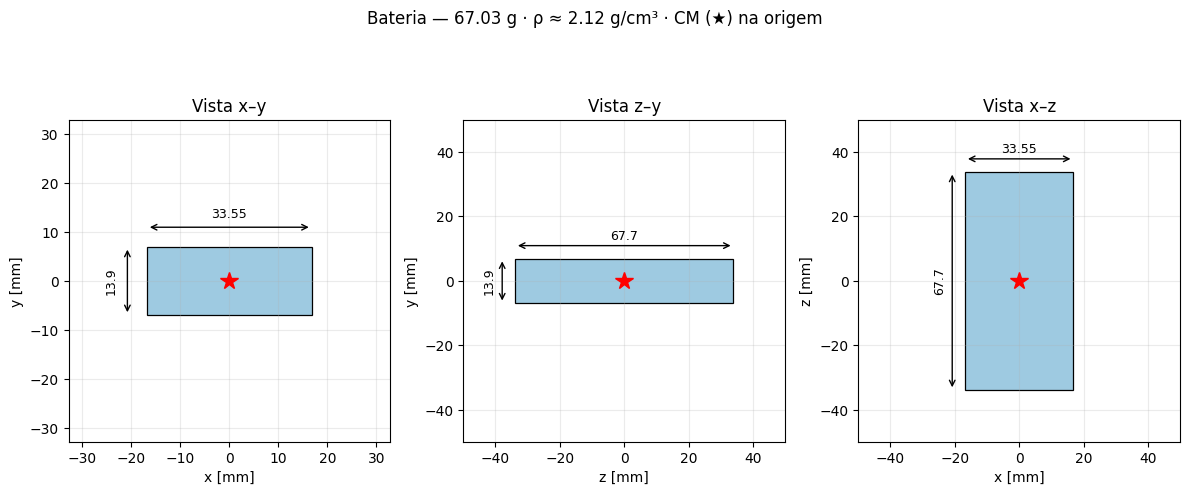

In [7]:
# ===================== BLOCO 7 — BATERIA =====================
# Sistema da bateria: origem no CM (sólido homogêneo), eixos ao longo das arestas: x = 33,55 · y = 13,9 · z = 67,7 mm.
# Para colocar a bateria no robô, defina a rotação R_bat (bateria → corpo) e a posição r_bat do seu CM no sistema do corpo.

# ---------- dados ----------
mm = sp.Rational(1, 1000)
m_bat = sp.Rational(6703, 100)/1000                                   # 67,03 g
a_b, b_b, c_b = sp.Rational(3355, 100)*mm, sp.Rational(139, 10)*mm, sp.Rational(677, 10)*mm

V_bat   = a_b*b_b*c_b
rho_bat = m_bat/V_bat
print(f'Volume = {float(V_bat)*1e6:.2f} cm³   ·   densidade média = {float(rho_bat)/1000:.2f} g/cm³')

# ---------- equações ----------
mb_, a_, b_, c_ = sp.symbols('m a b c')
print('\n1) Tensor de um paralelepípedo homogêneo no CM (eixos principais = arestas)')
eq(r'I^*', I_paralelepipedo(mb_, a_, b_, c_))
I_bat = I_paralelepipedo(m_bat, a_b, b_b, c_b)
print('\n2) Valores')
eq(r'I^*_{bateria}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_bat))
eq(r'I^*_{bateria}\,[\mathrm{kg\cdot m^2}]', I_bat.applyfunc(lambda x: sp.N(x, 5)))

# ---------- montagem no robô (AJUSTAR) ----------
R_bat = sp.eye(3)                                                      # rotação bateria → corpo (identidade = eixos alinhados)
r_bat = sp.Matrix([0, 0, 0])                                           # posição do CM da bateria no sistema do corpo
I_bat_corpo = girar_tensor(I_bat, R_bat)
print('\n3) Na montagem: I_corpo = R·I*·Rᵀ ; depois entra em compor(...) junto com as outras peças (o Steiner é feito lá)')
bateria = dict(nome='bateria', m=m_bat, r=r_bat, I=I_bat_corpo)

# ---------- desenho: três vistas ----------
f = lambda v: float(v)*1000
A, B, C = f(a_b), f(b_b), f(c_b)
fig, axs = plt.subplots(1, 3, figsize=(12, 5.2))
def vista(ax, w, h, lw_, lh_, titulo, xl, yl):
    ax.add_patch(plt.Rectangle((-w/2, -h/2), w, h, fc='#9ECAE1', ec='k', lw=.9))
    ax.plot(0, 0, 'r*', ms=13, zorder=5)
    ax.annotate('', xy=(-w/2, h/2 + 4), xytext=(w/2, h/2 + 4), arrowprops=dict(arrowstyle='<->')); ax.text(0, h/2 + 6, lw_, ha='center', fontsize=9)
    ax.annotate('', xy=(-w/2 - 4, -h/2), xytext=(-w/2 - 4, h/2), arrowprops=dict(arrowstyle='<->')); ax.text(-w/2 - 6, 0, lh_, rotation=90, ha='right', va='center', fontsize=9)
    m_ = max(w, h)/2 + 16; ax.set_xlim(-m_, m_); ax.set_ylim(-m_, m_); ax.set_aspect('equal'); ax.grid(alpha=.25)
    ax.set_title(titulo); ax.set_xlabel(xl); ax.set_ylabel(yl)
vista(axs[0], A, B, f'{A:.2f}', f'{B:.1f}', 'Vista x–y', 'x [mm]', 'y [mm]')
vista(axs[1], C, B, f'{C:.1f}', f'{B:.1f}', 'Vista z–y', 'z [mm]', 'y [mm]')
vista(axs[2], A, C, f'{A:.2f}', f'{C:.1f}', 'Vista x–z', 'x [mm]', 'z [mm]')
fig.suptitle(f'Bateria — {float(m_bat)*1000:.2f} g · ρ ≈ {float(rho_bat)/1000:.2f} g/cm³ · CM (★) na origem', y=0.99)
plt.tight_layout(); plt.show()

Densidade se seção circular: 1.00 g/cm³ · se seção quadrada: 0.79 g/cm³

1) Haste cilíndrica homogênea (eixo em z) no CM


<IPython.core.display.Math object>


2) Valores


<IPython.core.display.Math object>

<IPython.core.display.Math object>

I_axial / I_transversal = 2.59e-03  →  a haste se comporta como barra fina: I_t ≈ m·L²/12
Diferença relativa de I_t entre seção quadrada e circular: 0.043 %


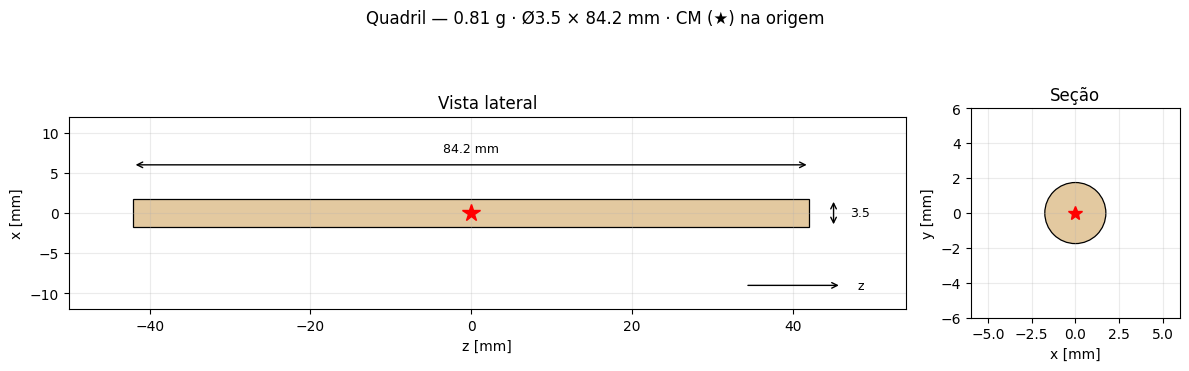

In [8]:
# ===================== BLOCO 8 — QUADRIL (haste) =====================
# Sistema da haste: origem no CM, eixo da haste ao longo de z. Para colocá-la no robô, ajuste R_quad (haste → corpo) e r_quad (CM no corpo).

# ---------- dados ----------
mm = sp.Rational(1, 1000)
m_quad = sp.Rational(81, 100)/1000                     # 0,81 g
d_quad, L_quad = sp.Rational(35, 10)*mm, sp.Rational(842, 10)*mm     # Ø/largura 3,5 mm · comprimento 84,2 mm
r_q = d_quad/2

# conferência de densidade: seção circular × quadrada (a foto não deixa claro qual é)
V_circ, V_quad = sp.pi*r_q**2*L_quad, d_quad**2*L_quad
print(f'Densidade se seção circular: {float(m_quad/V_circ)/1000:.2f} g/cm³ · se seção quadrada: {float(m_quad/V_quad)/1000:.2f} g/cm³')

# ---------- equações ----------
mq, r_, h_ = sp.symbols('m r h')
print('\n1) Haste cilíndrica homogênea (eixo em z) no CM')
eq(r'I^*', I_cilindro(mq, r_, h_))
I_quad = I_cilindro(m_quad, r_q, L_quad)
print('\n2) Valores')
eq(r'I^*_{quadril}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_quad))
eq(r'I^*_{quadril}\,[\mathrm{kg\cdot m^2}]', I_quad.applyfunc(lambda x: sp.N(x, 5)))
eps = float((I_quad[2, 2]/I_quad[0, 0]))
print(f'I_axial / I_transversal = {eps:.2e}  →  a haste se comporta como barra fina: I_t ≈ m·L²/12')
# a seção quadrada mudaria I_t em: (3r² vs a²) -> diferença relativa
I_t_quad = m_quad*(d_quad**2 + L_quad**2)/12
print(f'Diferença relativa de I_t entre seção quadrada e circular: {float(abs(I_t_quad - I_quad[0, 0])/I_quad[0, 0])*100:.3f} %')

# ---------- montagem no robô (AJUSTAR) ----------
R_quad = sp.eye(3)                                     # haste → corpo (identidade = eixo da haste ao longo de z)
r_quad = sp.Matrix([0, 0, 0])                          # CM da haste no sistema do corpo
I_quad_corpo = girar_tensor(I_quad, R_quad)
quadril = dict(nome='quadril', m=m_quad, r=r_quad, I=I_quad_corpo)

# ---------- desenho (escala real, mm) ----------
f = lambda v: float(v)*1000
Lm, dm = f(L_quad), f(d_quad)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[4, 1]))
ax1.add_patch(plt.Rectangle((-Lm/2, -dm/2), Lm, dm, fc='#E3C9A0', ec='k', lw=.9)); ax1.plot(0, 0, 'r*', ms=13, zorder=5)
ax1.annotate('', xy=(-Lm/2, 6), xytext=(Lm/2, 6), arrowprops=dict(arrowstyle='<->')); ax1.text(0, 7.5, f'{Lm:.1f} mm', ha='center', fontsize=9)
ax1.annotate('', xy=(Lm/2 + 3, -dm/2), xytext=(Lm/2 + 3, dm/2), arrowprops=dict(arrowstyle='<->')); ax1.text(Lm/2 + 5, 0, f'{dm:.1f}', va='center', fontsize=9)
ax1.annotate('', xy=(Lm/2 + 4, -9), xytext=(Lm/2 - 8, -9), arrowprops=dict(arrowstyle='->')); ax1.text(Lm/2 + 6, -9, 'z', ha='left', va='center', fontsize=9)
ax1.set_xlim(-Lm/2 - 8, Lm/2 + 12); ax1.set_ylim(-12, 12); ax1.set_aspect('equal'); ax1.grid(alpha=.25)
ax1.set_xlabel('z [mm]'); ax1.set_ylabel('x [mm]'); ax1.set_title('Vista lateral')
ax2.add_patch(plt.Circle((0, 0), dm/2, fc='#E3C9A0', ec='k', lw=.9)); ax2.plot(0, 0, 'r*', ms=10, zorder=5)
ax2.set_xlim(-6, 6); ax2.set_ylim(-6, 6); ax2.set_aspect('equal'); ax2.grid(alpha=.25)
ax2.set_xlabel('x [mm]'); ax2.set_ylabel('y [mm]'); ax2.set_title('Seção')
fig.suptitle(f'Quadril — {float(m_quad)*1000:.2f} g · Ø{dm:.1f} × {Lm:.1f} mm · CM (★) na origem', y=1.02)
plt.tight_layout(); plt.show()

Braços planos: o segmento inclinado avança 23.3 mm para dentro (> 22 mm até o centro) → as mãos se cruzam em z (±1.3 mm); a separação em x vem da inclinação das alavancas.
Manivela ψ = 0°: pino D em (x ; y) = (9.0 ; 0.0) mm · pino E em (-9.0 ; 0.0) mm  →  alavanca D: +11.2° (topo para trás) · alavanca E: -11.2° (topo para a frente)


Pés pendurados (θ=0): y ≈ -121 mm · θ_perna que reproduz a foto (−99 mm): ≈ 28°
  mão D (ápice do gancho): x =   21.3  y =   62.3  z =   -1.3 mm
  mão E (ápice do gancho): x =  -21.3  y =   62.3  z =    1.3 mm
Instâncias (sistema do corpo; +x = costas, −x = frente):
  motor    m = 100.000 g   CM = (   0.00 ;  -23.18 ;    0.01) mm
  quadril  m =   0.810 g   CM = (   0.00 ;  -45.50 ;    0.00) mm
  ombro D  m =   0.830 g   CM = (   4.09 ;    0.00 ;   15.58) mm
  ombro E  m =   0.830 g   CM = (  -4.09 ;    0.00 ;  -15.58) mm
  braço D  m =   2.000 g   CM = (  10.27 ;    6.44 ;   15.32) mm
  braço E  m =   2.000 g   CM = ( -10.27 ;    6.44 ;  -15.32) mm
  perna D  m =   1.500 g   CM = ( -21.65 ;  -86.71 ;   24.00) mm
  perna E  m =   1.500 g   CM = ( -21.65 ;  -86.71 ;  -24.00) mm
  bateria  m =  67.030 g   CM = (  18.20 ;  -19.70 ;    0.00) mm


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Momentos principais no CM [g·mm²]: [34244.7, 97556.6, 103389.0]


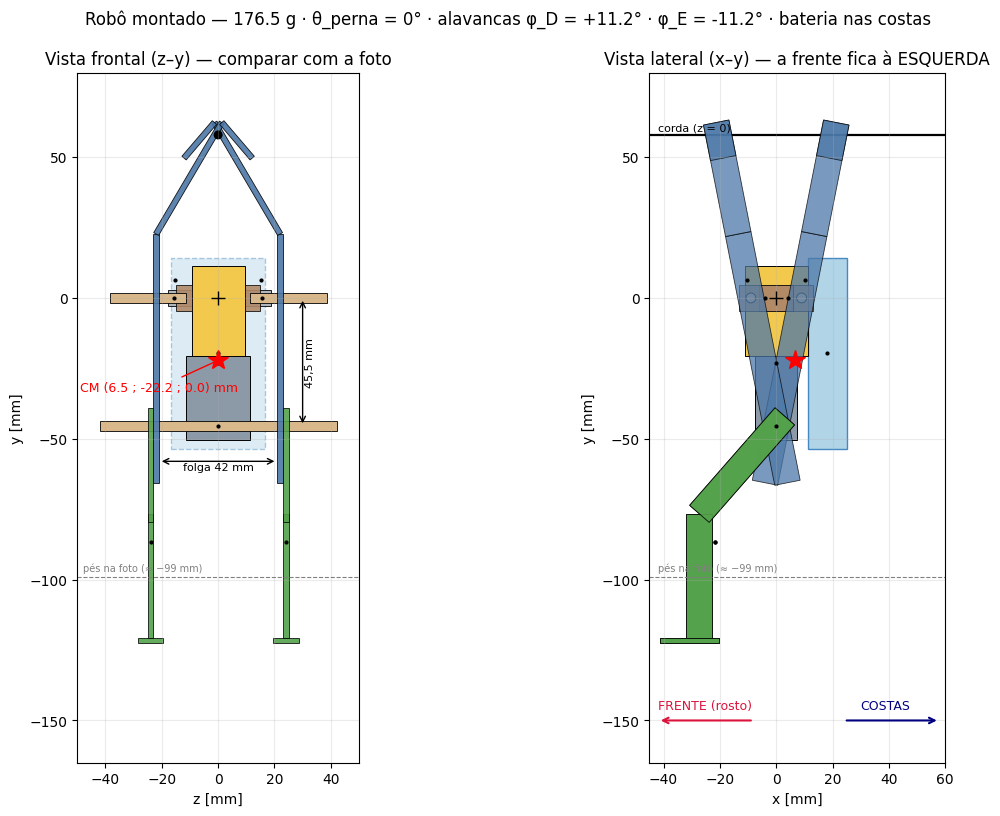

In [9]:
# ===================== BLOCO 9 — ROBÔ COMPLETO (montagem) =====================
# Sistema do corpo: origem O no centro do eixo de saída do motor · z ao longo desse eixo (+ à direita na vista frontal da foto)
# y para cima · x para o fundo:  +x = COSTAS (afasta-se de quem olha a foto frontal)  ·  −x = FRENTE (lado do rosto).  D = z>0 · E = z<0.
# Braços: planos no plano frontal (z = ±22 mm) e rígidos; funcionam como ALAVANCAS que giram em torno do eixo do quadril, acionadas pelos
#         pinos das manivelas. As manivelas estão defasadas de 180°: enquanto um braço vai para trás (+x) o outro vai para a frente (−x).
#         Pernas: planas no plano lateral (x–y), penduradas do eixo do quadril, com o pé (dedão) para a FRENTE e o calcanhar atrás.
#         Bateria nas costas (+x).

# ---------- parâmetros de montagem (mm, graus) — EDITAR ----------
z_membro    = 22.0     # plano de cada membro: folga de 42 mm entre os palitos (cota da foto) + 2 mm de espessura → ±22 mm
y_quadril   = -45.5    # eixo do quadril abaixo do eixo do motor (cota de 45,5 mm da foto)
y_juncao    = 24.0     # altura da dobra do braço (fim do segmento de 90 mm), lida na foto
dz_perna    = 2.0      # a perna fica por fora do braço
d_furo_perna = 4.6     # mm: do eixo do quadril até a extremidade superior da perna ("ligeiramente acima") — ESTIMADO; medir
theta_perna = 0.0      # balanço das pernas em torno do eixo do quadril [°]; positivo = o pé sobe para a FRENTE (−x); 0 = pendurada
psi = 0.0              # ângulo da manivela [°]: o pino D fica em ψ e o pino E em ψ+180° (alternados). 0° = pinos no nível do eixo (como na foto):
                       # braços a ±11,2° (um para trás, outro para a frente); 90° = pinos na vertical: braços alinhados na vertical
alinhar_maos = False   # opção extra (não é o mecanismo real): gira a parte de cima de cada braço em torno da vertical para as mãos caírem em z = 0
sentido_maos = +1      # só vale com alinhar_maos=True
incluir_bateria = True # bateria nas costas do boneco (+x)
y_bat = (11.2 - 50.6)/2                 # centralizada no conjunto caixa+motor (y de +11,2 a −50,6 mm) — ESTIMADO
x_bat = 22.5/2 + float(b_b)*1000/2      # encostada na face traseira da caixa (22,5/2) + metade da espessura da bateria (13,9/2)
z_bat = 0.0                             # centrada em z (33,55 mm cabem entre os membros: ±16,8 < ±22)
z_cx = 9.4                              # metade da espessura da caixa de redução (18,8/2)

# ---------- rotações e colocação ----------
mmf = 1e-3
fl  = lambda A: sp.Matrix(A).applyfunc(lambda x: sp.N(x, 15))
def Rzg(a):  a = np.deg2rad(a); return sp.Matrix([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
def Ryg(a):  a = np.deg2rad(a); return sp.Matrix([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])

pbm = lambda R, t, v: np.array([float(c) for c in (sp.Matrix(t) + sp.Matrix(R)*sp.Matrix(v))])*1000      # ponto da peça → corpo [mm]

def colocar(nome, b, R, t):
    """Coloca uma peça no corpo: r = t + R·r_peça ; I = R·I·Rᵀ  (R própria: nunca espelhar uma peça real)."""
    R, t = sp.Matrix(R), sp.Matrix(t)
    return dict(nome=nome, m=b['m'], r=t + R*b['r'], I=R*b['I']*R.T, R=R, t=t)

# ---------- braço com as mãos alinhadas na corda ----------
J    = fl(pecas[0]['fim'])                                   # junção do segmento longo com o inclinado (sistema do braço)
h    = float(pecas[1]['L'])*1000*float(sp.sin(pecas[1]['alpha']))   # alcance horizontal do segmento inclinado [mm]
phi0 = float(np.degrees(np.arccos(z_membro/h))) if (alinhar_maos and h > z_membro) else 0.0
phi  = -sentido_maos*phi0                                    # giro da parte de cima em torno do eixo y do braço
pecas_braco = []
for k, sg in enumerate(pecas):                               # segmentos do braço (bloco 3)
    d_ = dict(m=float(sg['m']), r=fl(sg['r']), I=fl(sg['I']), ini=fl(sg['ini']), fim=fl(sg['fim']), L=sg['L'])
    if k > 0:                                                # inclinado + gancho giram juntos em torno da vertical que passa pela junção
        Rj = Ryg(phi)
        d_['r'] = J + Rj*(d_['r'] - J); d_['I'] = Rj*d_['I']*Rj.T
        d_['ini'] = J + Rj*(d_['ini'] - J); d_['fim'] = J + Rj*(d_['fim'] - J)
    pecas_braco.append(d_)
M_br, rcm_br, I_br = compor(pecas_braco)
if alinhar_maos:
    print(f'Mãos: alcance horizontal do segmento inclinado = {h:.1f} mm ; precisa de {z_membro:.0f} mm até a corda → giro de {phi0:.1f}° fora do plano')
else:
    print(f'Braços planos: o segmento inclinado avança {h:.1f} mm para dentro (> {z_membro:.0f} mm até o centro) → as mãos se cruzam em z (±{h - z_membro:.1f} mm); '
          f'a separação em x vem da inclinação das alavancas.')

# ---------- dados das peças (resultados dos blocos anteriores, no sistema próprio de cada peça) ----------
base = dict(
    braco   = dict(m=M_br,           r=rcm_br,         I=I_br),             # bloco 3 (com as mãos alinhadas)
    perna   = dict(m=float(M_perna), r=fl(rcm_perna),  I=fl(I_perna)),      # bloco 4
    ombro   = dict(m=float(M_omb),   r=fl(rcm_omb),    I=fl(I_omb)),        # bloco 5
    motor   = dict(m=float(M_mot),   r=fl(rcm_mot),    I=fl(I_mot)),        # bloco 6
    bateria = dict(m=float(m_bat),   r=sp.zeros(3, 1), I=fl(I_bat)),        # bloco 7
    quadril = dict(m=float(m_quad),  r=sp.zeros(3, 1), I=fl(I_quad)))       # bloco 8

# ---------- instâncias ----------
inst = [colocar('motor',   base['motor'],   sp.eye(3), [0, 0, 0]),
        colocar('quadril', base['quadril'], sp.eye(3), [0, y_quadril*mmf, 0]),
        colocar('ombro D', base['ombro'],   Rzg(psi),          [0, 0, +z_cx*mmf]),
        colocar('ombro E', base['ombro'],   Rzg(psi)*Ryg(180), [0, 0, -z_cx*mmf])]    # mesma peça, virada 180° em y: o pino E fica em ψ+180°

# ---- alavancas: cada braço gira em torno do eixo do quadril e passa pelo pino da sua manivela ----
def angulo_alavanca(ombro):
    x_p, y_p = pbm(ombro['R'], ombro['t'], [9*mmf, 0, 1.83*mmf])[:2]       # pino no plano x–y do corpo [mm]
    return float(np.degrees(np.arctan2(x_p, y_p - y_quadril))), (x_p, y_p)   # φ > 0: topo do braço para trás (+x)
phi_D, pino_D = angulo_alavanca(inst[2]); phi_E, pino_E = angulo_alavanca(inst[3])
print(f'Manivela ψ = {psi:.0f}°: pino D em (x ; y) = ({pino_D[0]:.1f} ; {pino_D[1]:.1f}) mm · pino E em ({pino_E[0]:.1f} ; {pino_E[1]:.1f}) mm'
      f'  →  alavanca D: {phi_D:+.1f}° (topo para {"trás" if phi_D > 0 else "a frente"}) · alavanca E: {phi_E:+.1f}° (topo para {"trás" if phi_E > 0 else "a frente"})')

y0 = y_juncao - 90.0                                                   # extremo livre (inferior) do segmento longo do braço
R_bD = sp.Matrix([[0, 0, 1], [0, 1, 0], [-1, 0, 0]])                   # x_braço → −z (dobra para dentro) ; z_braço → +x
R_bE = sp.Matrix([[0, 0, -1], [0, 1, 0], [1, 0, 0]])                   # x_braço → +z (dobra para dentro) ; z_braço → −x
P_quad = sp.Matrix([0, y_quadril*mmf, 0])                              # eixo do quadril (reta ao longo de z por x = 0, y = y_quadril)
def braco_alavanca(nome, R_b, t_b, phi_deg):
    Rt = Rzg(-phi_deg)                                                 # giro em torno de z pelo eixo do quadril: topo para +x quando φ > 0
    return colocar(nome, base['braco'], Rt*R_b, P_quad + Rt*(sp.Matrix(t_b) - P_quad))
inst += [braco_alavanca('braço D', R_bD, [0, y0*mmf, +z_membro*mmf], phi_D),
         braco_alavanca('braço E', R_bE, [0, y0*mmf, -z_membro*mmf], phi_E)]

fim_sup = fl(haste_sup['fim'])                                         # extremidade superior da perna (fim da haste inclinada), sistema da perna
u_sup   = fl(sp.Matrix([sp.sin(haste_sup['alpha']), sp.cos(haste_sup['alpha']), 0]))   # direção da haste inclinada (de baixo para cima)
pivo_perna = fim_sup - d_furo_perna*mmf*u_sup                          # ponto da perna que coincide com o eixo do quadril
R_l = Rzg(-theta_perna)*Ryg(180)          # Ry(180°): o dedão (+x da perna) passa a apontar para a FRENTE (−x); depois, o balanço θ
for lado, nome in ((+1, 'D'), (-1, 'E')):
    fixa = sp.Matrix([0, y_quadril*mmf, lado*(z_membro + dz_perna)*mmf])   # a perna gira em torno do eixo do quadril
    inst.append(colocar('perna ' + nome, base['perna'], R_l, fixa - R_l*pivo_perna))
if incluir_bateria:
    R_bat = sp.Matrix([[0, 1, 0], [0, 0, 1], [1, 0, 0]])               # bateria: x(33,55) → z · y(13,9) → x (espessura, para as costas) · z(67,7) → y (vertical)
    inst.append(colocar('bateria', base['bateria'], R_bat, [x_bat*mmf, y_bat*mmf, z_bat*mmf]))

# balanço que reproduziria a altura dos pés da foto (≈ −99 mm, medida a partir de y=0)
y_pe = lambda th_: float((Rzg(-th_)*Ryg(180)*(-pivo_perna))[1])*1000 + y_quadril
ths = np.linspace(0, 90, 901); theta_foto = ths[np.argmin([abs(y_pe(a_) + 99) for a_ in ths])]
print(f'Pés pendurados (θ=0): y ≈ {y_pe(0):.0f} mm · θ_perna que reproduz a foto (−99 mm): ≈ {theta_foto:.0f}°')

# ---------- composição ----------
M_rob, rcm_rob, I_rob = compor(inst)
I_O_rob = steiner(I_rob, M_rob, rcm_rob)                               # tensor em O (eixo de saída do motor)

tem = {p['nome']: p for p in inst}
for nome in ('braço D', 'braço E'):
    ap = pbm(tem[nome]['R'], tem[nome]['t'], pecas_braco[1]['fim'])
    print(f'  mão {nome[-1]} (ápice do gancho): x = {ap[0]:6.1f}  y = {ap[1]:6.1f}  z = {ap[2]:6.1f} mm')
print('Instâncias (sistema do corpo; +x = costas, −x = frente):')
for p in inst:
    print(f"  {p['nome']:8s} m = {p['m']*1000:7.3f} g   CM = ({p['r'][0]*1000:7.2f} ; {p['r'][1]*1000:7.2f} ; {p['r'][2]*1000:7.2f}) mm")
eq('M', r'\sum_i m_i', sp.N(M_rob*1000, 5), r'@\mathrm{g}')
eq(r'\mathbf{r}_{CM}', r'\frac{1}{M}\sum_i m_i\,\mathbf{r}_i', (rcm_rob*1000).applyfunc(lambda x: sp.N(x, 4)), r'@\mathrm{mm}')
eq(r'I^*_{rob\hat o}', r'\sum_i\left[R_i I_i R_i^{T} + m_i\left(|\mathbf{d}_i|^2\,\mathbb{1}-\mathbf{d}_i\mathbf{d}_i^{T}\right)\right]', r'@\text{com }\mathbf{d}_i=\mathbf{r}_i-\mathbf{r}_{CM}')
eq(r'I^*_{rob\hat o}\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_rob))
eq(r'I^*_{rob\hat o}\,[\mathrm{kg\cdot m^2}]', I_rob.applyfunc(lambda x: sp.N(x, 5)))
eq(r'I_O\,[\mathrm{g\cdot mm^2}]', em_g_mm2(I_O_rob))
print('Momentos principais no CM [g·mm²]:', [round(v, 1) for v in sorted(float(sp.re(v))*1e9 for v in I_rob.eigenvals())])

# ---------- desenho: vista frontal (z–y, como na foto) e lateral (x–y) ----------
fm = lambda v: np.array([float(c) for c in v])*1000
def pb(R, t, v): return fm(t + R*sp.Matrix(v))
def seg_poly(p0, p1, wd):
    p0, p1 = np.array(p0, float), np.array(p1, float); u = (p1 - p0)/max(np.linalg.norm(p1 - p0), 1e-9); n = np.array([-u[1], u[0]])
    return np.array([p0 + wd/2*n, p1 + wd/2*n, p1 - wd/2*n, p0 - wd/2*n])
fig, (axF, axL) = plt.subplots(1, 2, figsize=(13, 8.2))
ca = dict(motor='#F2C94C', mot2='#8C99A6', ombro='#B08968', braco='#4C78A8', perna='#54A24B', rod='#D9B98B')
Rect = plt.Rectangle
# bateria (atrás: tracejada na frontal)
if incluir_bateria:
    Bz, By, Bx = float(a_b)*1000, float(c_b)*1000, float(b_b)*1000
    axF.add_patch(Rect((z_bat - Bz/2, y_bat - By/2), Bz, By, fc='#9ECAE1', ec='#2171B5', lw=1, ls='--', alpha=.35, zorder=0))
    axL.add_patch(Rect((x_bat - Bx/2, y_bat - By/2), Bx, By, fc='#9ECAE1', ec='#2171B5', lw=1, alpha=.8, zorder=1))
# motor
axF.add_patch(Rect((-9.4, -20.6), 18.8, 31.8, fc=ca['motor'], ec='k', lw=.7)); axF.add_patch(Rect((-11.25, -50.6), 22.5, 30.0, fc=ca['mot2'], ec='k', lw=.7))
axF.add_patch(Rect((-17.9, -2.7), 8.5, 5.4, fc='#B0B7BF', ec='k', lw=.6)); axF.add_patch(Rect((9.4, -2.7), 9.5, 5.4, fc='#B0B7BF', ec='k', lw=.6))
axL.add_patch(Rect((-11.25, -20.6), 22.5, 31.8, fc=ca['motor'], ec='k', lw=.7)); axL.add_patch(Rect((-7.5, -50.6), 15.0, 30.0, fc=ca['mot2'], ec='k', lw=.7))
# quadril
axF.add_patch(Rect((-42.1, y_quadril - 1.75), 84.2, 3.5, fc=ca['rod'], ec='k', lw=.6)); axL.add_patch(plt.Circle((0, y_quadril), 1.75, fc=ca['rod'], ec='k', lw=.6))
# manivelas
for nome in ('ombro D', 'ombro E'):
    p = tem[nome]; R, t = p['R'], p['t']
    cantos = np.array([pb(R, t, [x*mmf, y*mmf, 0])[:2] for x, y in ((-6, -4.6), (13.2, -4.6), (13.2, 4.6), (-6, 4.6))])
    axL.add_patch(plt.Polygon(cantos, fc=ca['ombro'], ec='k', lw=.6, alpha=.8))
    z_in, z_out = pb(R, t, [0, 0, 0])[2], pb(R, t, [0, 0, 5.5*mmf])[2]
    axF.add_patch(Rect((min(z_in, z_out), cantos[:, 1].min()), abs(z_out - z_in), np.ptp(cantos[:, 1]), fc=ca['ombro'], ec='k', lw=.6, alpha=.9))
    pino0, pino1 = pb(R, t, [9*mmf, 0, 1.83*mmf]), pb(R, t, [9*mmf, 0, 29.1*mmf])
    axF.add_patch(Rect((min(pino0[2], pino1[2]), pino0[1] - 1.75), abs(pino1[2] - pino0[2]), 3.5, fc=ca['rod'], ec='k', lw=.6))
    axL.add_patch(plt.Circle((pino0[0], pino0[1]), 1.75, fc=ca['rod'], ec='k', lw=.6))
# braços (com as mãos giradas para a corda)
wx = 9.2*np.cos(np.deg2rad(phi)) + 2.0*abs(np.sin(np.deg2rad(phi)))               # extensão em x de um palito girado
for nome in ('braço D', 'braço E'):
    p = tem[nome]
    for k, sg in enumerate(pecas_braco):
        a, b = pb(p['R'], p['t'], sg['ini']), pb(p['R'], p['t'], sg['fim'])
        axF.add_patch(plt.Polygon(seg_poly((a[2], a[1]), (b[2], b[1]), 2.0), fc=ca['braco'], ec='k', lw=.6, alpha=.9))
        axL.add_patch(plt.Polygon(seg_poly((a[0], a[1]), (b[0], b[1]), 9.2 if k == 0 else wx), fc=ca['braco'], ec='k', lw=.6, alpha=.75))
# corda (z = 0, ao longo de x) na altura do vão do gancho
y_corda = max(pbm(tem[n_]['R'], tem[n_]['t'], pecas_braco[1]['fim'])[1] for n_ in ('braço D', 'braço E')) - 4.4
axF.add_patch(plt.Circle((0, y_corda), 1.6, fc='k')); axL.axhline(y_corda, color='k', lw=1.6, ls='-', zorder=0.5); axL.text(-42, y_corda + 1.5, 'corda (z = 0)', fontsize=8)
# pernas
for nome, lado in (('perna D', +1), ('perna E', -1)):
    p = tem[nome]; zc = lado*(z_membro + dz_perna)
    for sg, esp_plano, larg_z in zip(pecas_perna, (float(t_h)*1000, float(t_h)*1000, float(t_p)*1000), (float(w_h)*1000, float(w_h)*1000, float(w_p)*1000)):
        a, b = pb(p['R'], p['t'], sg['ini']), pb(p['R'], p['t'], sg['fim'])
        poly = seg_poly((a[0], a[1]), (b[0], b[1]), esp_plano)
        axL.add_patch(plt.Polygon(poly, fc=ca['perna'], ec='k', lw=.6, alpha=.9))
        axF.add_patch(Rect((zc - larg_z/2, poly[:, 1].min()), larg_z, np.ptp(poly[:, 1]), fc=ca['perna'], ec='k', lw=.6, alpha=.9))
# CM e referências da foto
cm = fm(rcm_rob)
for ax, ix, xl in ((axF, 2, 'z [mm]'), (axL, 0, 'x [mm]')):
    for p in inst: ax.plot(fm(p['r'])[ix], fm(p['r'])[1], '.', color='k', ms=4)
    ax.plot(cm[ix], cm[1], 'r*', ms=15, zorder=6); ax.plot(0, 0, 'k+', ms=10)
    ax.axhline(-99, color='gray', ls='--', lw=.8); ax.text(-48 if ix == 2 else -42, -97, 'pés na foto (≈ −99 mm)', fontsize=7, color='gray')
    ax.set_aspect('equal'); ax.grid(alpha=.25); ax.set_xlabel(xl); ax.set_ylabel('y [mm]'); ax.set_ylim(-165, 80)
axF.annotate('', xy=(-z_membro + 1, -58), xytext=(z_membro - 1, -58), arrowprops=dict(arrowstyle='<->')); axF.text(0, -61, 'folga 42 mm', ha='center', fontsize=8)
axF.annotate('', xy=(30, y_quadril), xytext=(30, 0), arrowprops=dict(arrowstyle='<->')); axF.text(31, y_quadril/2, '45,5 mm', rotation=90, va='center', fontsize=8)
axF.set_xlim(-50, 50); axL.set_xlim(-45, 60)
axL.annotate('', xy=(-42, -150), xytext=(-8, -150), arrowprops=dict(arrowstyle='->', lw=1.5, color='crimson')); axL.text(-42, -146, 'FRENTE (rosto)', fontsize=9, color='crimson')
axL.annotate('', xy=(58, -150), xytext=(24, -150), arrowprops=dict(arrowstyle='->', lw=1.5, color='navy')); axL.text(30, -146, 'COSTAS', fontsize=9, color='navy')
axF.set_title('Vista frontal (z–y) — comparar com a foto'); axL.set_title('Vista lateral (x–y) — a frente fica à ESQUERDA')
axF.annotate(f'CM ({cm[0]:.1f} ; {cm[1]:.1f} ; {cm[2]:.1f}) mm', (cm[2], cm[1]), xytext=(-49, -33), color='r', fontsize=9, arrowprops=dict(arrowstyle='-', color='r'))
fig.suptitle(f'Robô montado — {float(M_rob)*1000:.1f} g · θ_perna = {theta_perna:.0f}° · alavancas φ_D = {phi_D:+.1f}° · φ_E = {phi_E:+.1f}° · bateria {"nas costas" if incluir_bateria else "fora"}', y=0.99)
plt.tight_layout(); plt.show()


<IPython.core.display.Math object>

corpo                   m [g]          CM x ; y ; z [mm]   I*_zz [g·mm²]             pivô  I_pivô [g·mm²]
manivela D              0.830     4.09 ;    0.00 ;  15.58            28.8    eixo do motor            42.7
manivela E              0.830    -4.09 ;    0.00 ; -15.58            28.8    eixo do motor            42.7
alavanca D (braço)      2.000    10.27 ;    6.44 ;  15.32          3219.0  eixo do quadril          8825.0
alavanca E (braço)      2.000   -10.27 ;    6.44 ; -15.32          3219.0  eixo do quadril          8825.0
perna D                 1.500   -21.65 ;  -86.71 ;  24.00          1220.2  eixo do quadril          4471.2
perna E                 1.500   -21.65 ;  -86.71 ; -24.00          1220.2  eixo do quadril          4471.2
chassi (motor+quadril+bateria)  167.840     7.27 ;  -21.90 ;   0.01         74644.2    eixo do motor        164011.7

Chassi — tensor no CM [g·mm²]:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Com ω = 3.1416 rad/s constante (α = 0): |a_pino| = ω²·R = 0.0888 m/s²  ·  |v_pino| = ω·R = 28.3 mm/s

Ângulo da alavanca em função do ângulo da manivela:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

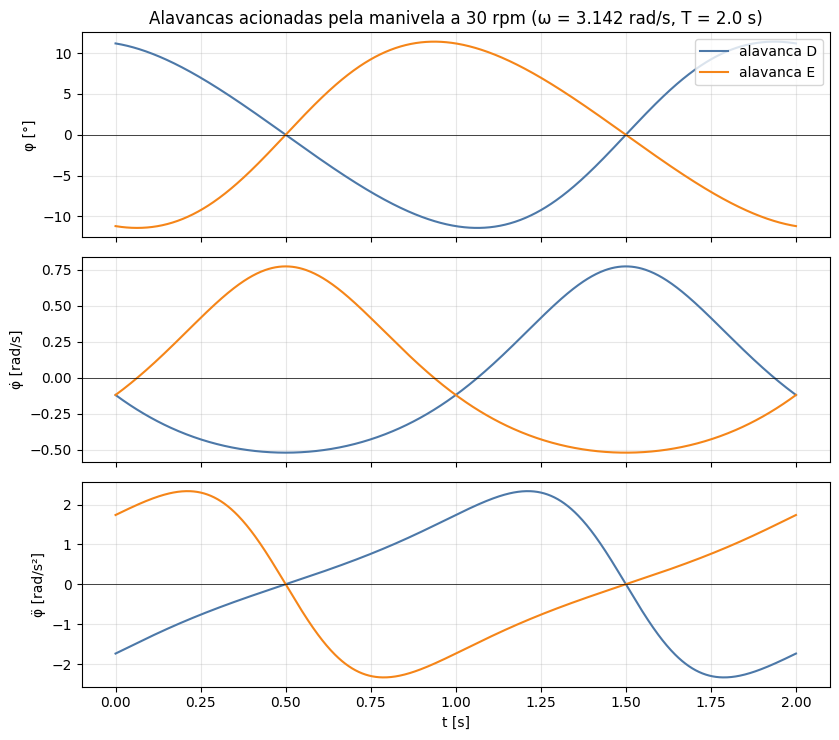

φ_D varia de -11.4° a 11.4°  ·  |φ̇|máx = 0.775 rad/s  ·  |φ̈|máx = 2.335 rad/s²
Em t = 0 (ψ = 0°): φ_D = +11.19°, φ_E = -11.19°  (conferir com o bloco 9)


In [10]:
# ===================== BLOCO 10 — CORPOS MÓVEIS E MANIVELA A 30 RPM =====================
# Parte A: massa, CM e inércia de cada corpo móvel em torno do seu pivô · Parte B: cinemática manivela → alavancas com ψ(t) = ψ0 + ω·t
from sympy.physics.vector import ReferenceFrame, Point, dynamicsymbols, vlatex

# ---------- dados ----------
rpm     = 30.0                                  # rotação da manivela (eixo de saída do motor) — SUPOSTO
sentido = +1                                    # +1: ψ cresce no sentido anti-horário em torno de +z (x → y); −1 inverte
omega_m = sentido*rpm*2*np.pi/60                # rad/s  (30 rpm = π rad/s → período de 2 s)
T_m     = 60.0/rpm

# ================= PARTE A — inércia de cada corpo móvel em torno do pivô =================
# Movimento no plano x–y: o que importa é o momento de inércia em torno do eixo z (paralelo ao eixo do motor). Ele não muda com o giro em torno de z.
P_quad = np.array([0.0, y_quadril])             # eixo do quadril (x, y) [mm]
P_eixo = np.array([0.0, 0.0])                   # eixo de saída do motor (x, y) [mm]
def Izz_pivo(p, pivo):                          # I_pivô = I*_zz + m·d²   [g·mm²]
    d2 = float(np.sum((fm(p['r'])[:2] - pivo)**2))
    return float(p['I'][2, 2])*1e9 + p['m']*1000*d2

chassi = compor([tem['motor'], tem['quadril']] + ([tem['bateria']] if incluir_bateria else []))
M_ch, rcm_ch, I_ch = chassi
corpos = [('manivela D', tem['ombro D'], P_eixo, 'eixo do motor'), ('manivela E', tem['ombro E'], P_eixo, 'eixo do motor'),
          ('alavanca D (braço)', tem['braço D'], P_quad, 'eixo do quadril'), ('alavanca E (braço)', tem['braço E'], P_quad, 'eixo do quadril'),
          ('perna D', tem['perna D'], P_quad, 'eixo do quadril'), ('perna E', tem['perna E'], P_quad, 'eixo do quadril')]

eq(r'I_{pivô}', r'I^*_{zz} + m\,d^2', r'@\text{(}d\text{: distância do CM ao eixo do pivô, no plano }x\text{–}y\text{)}')
print(f"{'corpo':20s} {'m [g]':>8s} {'CM x ; y ; z [mm]':>26s} {'I*_zz [g·mm²]':>15s} {'pivô':>16s} {'I_pivô [g·mm²]':>15s}")
for nome, p, pivo, nome_pivo in corpos:
    r = fm(p['r'])
    print(f"{nome:20s} {p['m']*1000:8.3f} {r[0]:8.2f} ;{r[1]:8.2f} ;{r[2]:7.2f} {float(p['I'][2, 2])*1e9:15.1f} {nome_pivo:>16s} {Izz_pivo(p, pivo):15.1f}")
rc = fm(rcm_ch)
print(f"{'chassi (motor+quadril' + ('+bateria)' if incluir_bateria else ')'):20s} {float(M_ch)*1000:8.3f} {rc[0]:8.2f} ;{rc[1]:8.2f} ;{rc[2]:7.2f} {float(I_ch[2, 2])*1e9:15.1f} {'eixo do motor':>16s} "
      f"{float(I_ch[2, 2])*1e9 + float(M_ch)*1000*float(np.sum(rc[:2]**2)):15.1f}")
print('\nChassi — tensor no CM [g·mm²]:'); eq(r'I^*_{chassi}', em_g_mm2(I_ch))

# ================= PARTE B — cinemática do mecanismo (eq. 2 do quadro) =================
# O pino da manivela é um ponto D de um corpo que gira em torno de um ponto E fixo (o eixo do motor): a = α × r + ω × (ω × r).
Rc_s = sp.symbols('R_c', positive=True)
N_  = ReferenceFrame('N'); C_ = N_.orientnew('C', 'Axis', [dynamicsymbols('psi'), N_.z])
O_  = Point('O'); O_.set_vel(N_, 0)
Pp  = O_.locatenew('P', Rc_s*C_.x); Pp.v2pt_theory(O_, N_, C_)
display(Math(r'\mathbf{v}^{P} = ' + vlatex(Pp.vel(N_)))); display(Math(r'\mathbf{a}^{P} = ' + vlatex(Pp.a2pt_theory(O_, N_, C_))))
print(f'Com ω = {omega_m:.4f} rad/s constante (α = 0): |a_pino| = ω²·R = {omega_m**2*9e-3:.4f} m/s²  ·  |v_pino| = ω·R = {abs(omega_m)*9e-3*1000:.1f} mm/s')

# Alavanca: passa pelo pino (a manivela o desliza em uma fenda ao longo do braço) e gira em torno do quadril.
tt, R_, h_, ps_ = sp.symbols('t R h psi', real=True)
phi_D_sym = sp.atan2(R_*sp.cos(ps_), R_*sp.sin(ps_) + h_)                   # φ > 0: topo do braço para trás (+x)
phi_E_sym = phi_D_sym.subs(ps_, ps_ + sp.pi)                               # o pino E está 180° adiante
print('\nÂngulo da alavanca em função do ângulo da manivela:')
eq(r'\varphi_D(\psi)', phi_D_sym); eq(r'\varphi_E(\psi)', r'\varphi_D(\psi+\pi)')
dphi = sp.simplify(sp.diff(phi_D_sym, ps_)); eq(r'\frac{d\varphi_D}{d\psi}', dphi)
eq(r'\dot\varphi_D', r'\frac{d\varphi_D}{d\psi}\,\dot\psi', r'@\;;\quad \ddot\varphi_D = \frac{d^2\varphi_D}{d\psi^2}\,\dot\psi^2 + \frac{d\varphi_D}{d\psi}\,\ddot\psi')

psi0 = np.deg2rad(psi)
vals = {R_: 9e-3, h_: 45.5e-3}
psi_t = psi0 + omega_m*tt
def serie(phi_sym):
    f0 = phi_sym.subs(vals).subs(ps_, psi_t)
    return [sp.lambdify(tt, e, 'numpy') for e in (f0, sp.diff(f0, tt), sp.diff(f0, tt, 2))]
fD, fE = serie(phi_D_sym), serie(phi_E_sym)

tv = np.linspace(0, T_m, 801)
fig, ax = plt.subplots(3, 1, figsize=(8.5, 7.5), sharex=True)
for f_, nome, cor in ((fD, 'alavanca D', '#4C78A8'), (fE, 'alavanca E', '#F58518')):
    ax[0].plot(tv, np.degrees(f_[0](tv)), color=cor, label=nome); ax[1].plot(tv, f_[1](tv), color=cor); ax[2].plot(tv, f_[2](tv), color=cor)
ax[0].set_ylabel('φ [°]'); ax[1].set_ylabel('φ̇ [rad/s]'); ax[2].set_ylabel('φ̈ [rad/s²]'); ax[2].set_xlabel('t [s]')
ax[0].legend(loc='upper right'); ax[0].set_title(f'Alavancas acionadas pela manivela a {rpm:.0f} rpm (ω = {omega_m:.3f} rad/s, T = {T_m:.1f} s)')
for a in ax: a.grid(alpha=.3); a.axhline(0, color='k', lw=.5)
plt.tight_layout(); plt.show()
print(f'φ_D varia de {np.degrees(fD[0](tv).min()):.1f}° a {np.degrees(fD[0](tv).max()):.1f}°  ·  |φ̇|máx = {np.abs(fD[1](tv)).max():.3f} rad/s  ·  |φ̈|máx = {np.abs(fD[2](tv)).max():.3f} rad/s²')
print(f'Em t = 0 (ψ = {psi:.0f}°): φ_D = {np.degrees(fD[0](0.0)):+.2f}°, φ_E = {np.degrees(fE[0](0.0)):+.2f}°  (conferir com o bloco 9)')


Equações simbólicas montadas: M(q) 5×5, c(q, q̇, t), restrições das mãos D e E  (7 corpos, 176.5 g)


Verificação Newton-Euler (Kane) × Lagrange: erro relativo máximo = 1.72e-16
Equilíbrio pendurado pela mão E: arfagem θ = -18.6° · pernas θ_D = 46.4°, θ_E = 46.4°


Simulação concluída em 3.3 s · 7 trocas de mão · violação máxima da restrição = 0.079 mm


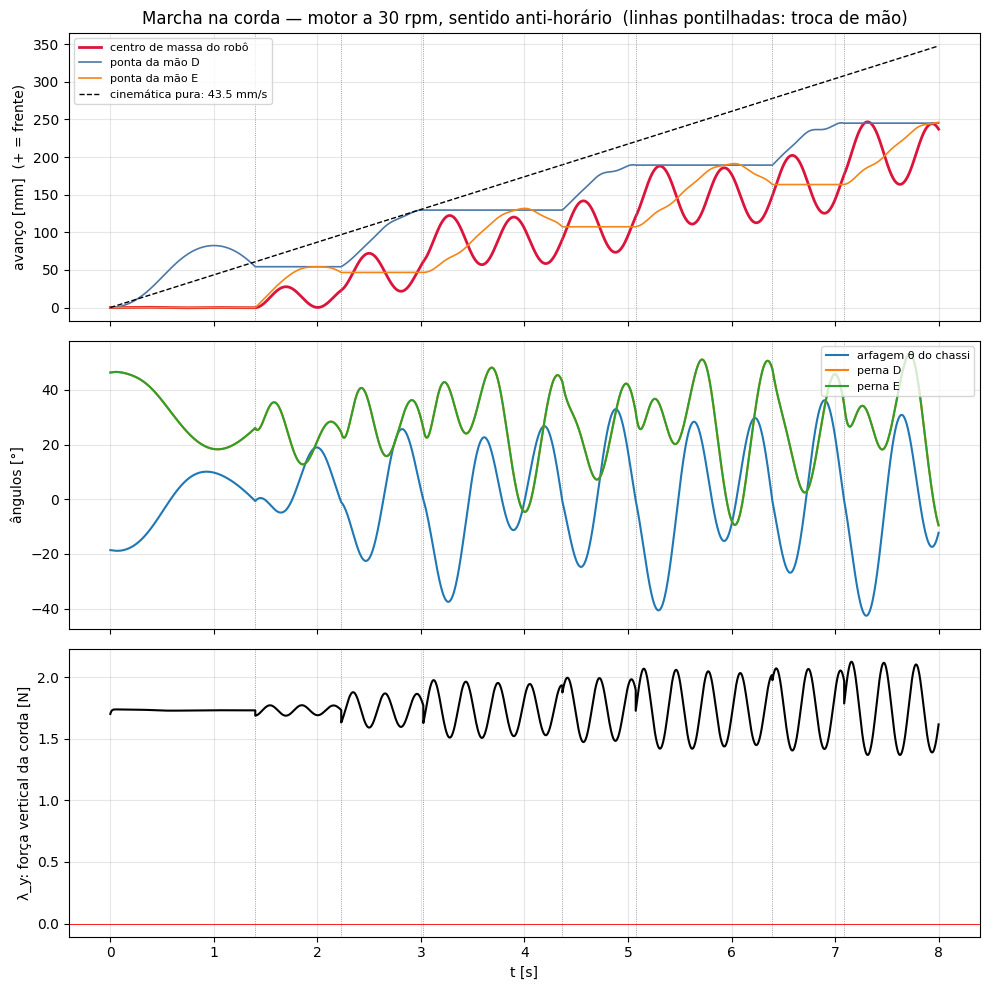

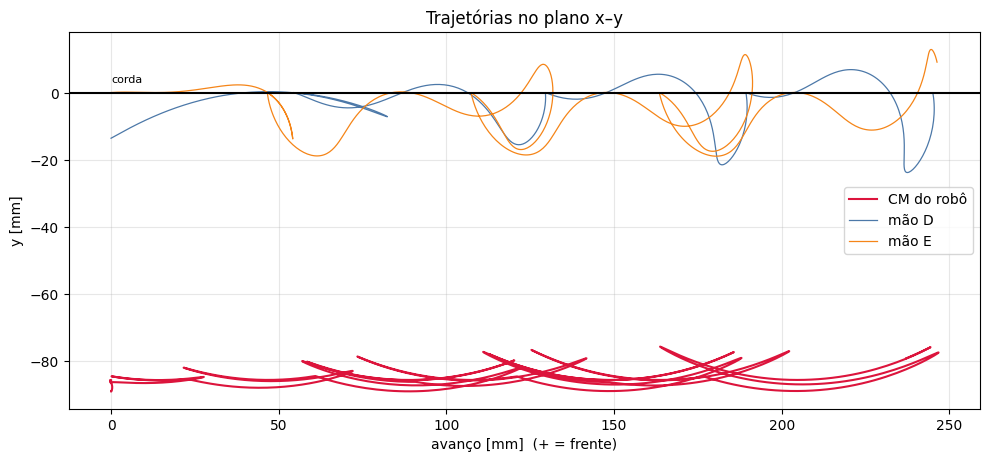

Avanço do CM em 8 s: 237.1 mm  ·  velocidade média na última volta: 33.0 mm/s  (cinemática pura: 43.5 mm/s)
Avanço da mão D: 245.1 mm · da mão E: 246.3 mm · variação da altura do CM: 13.4 mm
Força vertical da corda λ_y: mín = 1.368 N, máx = 2.124 N  (peso total = 1.731 N)
Trocas de mão (instante · mão · energia dissipada no impacto): 1.40 s · D · -0.02 mJ | 2.23 s · E · 0.11 mJ | 3.02 s · D · 0.80 mJ | 4.37 s · E · 0.33 mJ | 5.07 s · D · 1.86 mJ | 6.39 s · E · 0.29 mJ | 7.09 s · D · 2.46 mJ


In [11]:
# ===================== BLOCO 11 — MODELO DINÂMICO PLANO (Newton-Euler) E MARCHA NA CORDA =====================
# Plano x–y (x: costas, y: cima); a corda é a reta y = y_corda ao longo de x. Corpos:
#   chassi (motor + quadril + bateria): 3 graus de liberdade no plano (x_O, y_O, θ);  manivelas: ψ(t) = ψ0 + ω·t (prescrito, 30 rpm);
#   alavancas (braços): φ_D(ψ), φ_E(ψ) em torno do quadril (prescritos pela fenda do pino);  pernas: pêndulos livres no quadril (θ_D, θ_E).
# Contato: a mão engatada é um PINO preso a um ponto da corda (reta y = 0). A mão DESEJADA troca a cada meia volta da manivela (E se sin ψ > 0, D se sin ψ < 0);
# ela engata quando a ponta sobe até a corda (cruzamento de y = 0 de baixo para cima) e a troca é um impacto plástico (a nova mão para na corda). Equações: composição de velocidades/acelerações (eqs. 1 e 2 do quadro, com os termos
# relativos NÃO riscados nas alavancas) + Euler (dH/dt = I·α + ω×(I·ω)), projetados nas velocidades generalizadas (Kane).
from sympy.physics.vector import ReferenceFrame, Point, dynamicsymbols, outer
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
import time as _time

g_acc    = 9.81
c_perna  = 5.0e-5          # N·m·s/rad: amortecimento viscoso nos quadris das pernas (≈ 45% do crítico de cada perna) — SUPOSTO
c_chassi = 1.0e-4          # N·m·s/rad: amortecimento da arfagem do chassi (≈ 0,4% do crítico: quase sem atrito) — SUPOSTO. O avanço DEPENDE dele: edite e rode de novo
T_total  = 8.0             # s simulados
tdyn     = dynamicsymbols._t

# ---------- dados numéricos dos corpos (a partir dos blocos 9 e 10) ----------
mmf = 1e-3
def coords_rot(vxy_mm, ang_deg):                       # coordenadas (m) de um vetor no corpo, num referencial girado de −ang (ang em graus)
    a, b = vxy_mm; c, s = np.cos(np.deg2rad(ang_deg)), np.sin(np.deg2rad(ang_deg))
    return (a*c - b*s)*mmf, (a*s + b*c)*mmf
hip = np.array([0.0, y_quadril])
m_ch, Izz_ch = float(M_ch), float(I_ch[2, 2]); xch, ych = float(rcm_ch[0]), float(rcm_ch[1])
d_cD = fm(tem['ombro D']['r'])[:2]; d_cE = fm(tem['ombro E']['r'])[:2]
cD = coords_rot(d_cD, -psi); cE = coords_rot(d_cE, -(psi + 180))                  # CM das manivelas no referencial da manivela
m_cr, Izz_cr = tem['ombro D']['m'], float(tem['ombro D']['I'][2, 2])
def rel_quad(nome, ang_corr=0.0):
    d = fm(tem[nome]['r'])[:2] - hip
    c, s = np.cos(np.deg2rad(ang_corr)), np.sin(np.deg2rad(ang_corr)); return np.array([d[0]*c - d[1]*s, d[0]*s + d[1]*c])
lvD = coords_rot(rel_quad('braço D'), phi_D); lvE = coords_rot(rel_quad('braço E'), phi_E)    # CM das alavancas no referencial da alavanca
m_lv, Izz_lv = tem['braço D']['m'], float(tem['braço D']['I'][2, 2])
apD = pbm(tem['braço D']['R'], tem['braço D']['t'], pecas_braco[1]['fim'])[:2] - hip; apE = pbm(tem['braço E']['R'], tem['braço E']['t'], pecas_braco[1]['fim'])[:2] - hip
haD = coords_rot(apD, phi_D); haE = coords_rot(apE, phi_E)                          # ápice da mão no referencial da alavanca
lgD = rel_quad('perna D', theta_perna); lgE = rel_quad('perna E', theta_perna)       # CM das pernas (pendentes) relativo ao quadril
lgD = (lgD[0]*mmf, lgD[1]*mmf); lgE = (lgE[0]*mmf, lgE[1]*mmf)
m_lg, Izz_lg = tem['perna D']['m'], float(tem['perna D']['I'][2, 2])
y_h = y_quadril*mmf
Rc_, hh_ = 9e-3, 45.5e-3
psi0, omg = np.deg2rad(psi), omega_m
psi_t  = psi0 + omg*tdyn
phiD_t = sp.atan2(Rc_*sp.cos(psi_t), Rc_*sp.sin(psi_t) + hh_)                        # φ>0: topo para trás (+x)
phiE_t = sp.atan2(-Rc_*sp.cos(psi_t), -Rc_*sp.sin(psi_t) + hh_)

# ---------- cinemática (composição de movimentos) ----------
qs = list(dynamicsymbols('x_O y_O theta theta_D theta_E')); xO, yO, th, thD, thE = qs
N_  = ReferenceFrame('N'); P0 = Point('P0'); P0.set_vel(N_, 0)
B_  = N_.orientnew('B', 'Axis', [th, N_.z])                                         # chassi
O_  = P0.locatenew('O', xO*N_.x + yO*N_.y)                                          # centro do eixo de saída
H_  = O_.locatenew('H', y_h*B_.y); H_.v2pt_theory(O_, N_, B_)                       # eixo do quadril (fixo no chassi)
CrD = B_.orientnew('CrD', 'Axis', [psi_t, B_.z]); CrE = B_.orientnew('CrE', 'Axis', [psi_t + sp.pi, B_.z])     # manivelas (prescritas)
LvD = B_.orientnew('LvD', 'Axis', [-phiD_t, B_.z]); LvE = B_.orientnew('LvE', 'Axis', [-phiE_t, B_.z])         # alavancas (prescritas)
LgD = B_.orientnew('LgD', 'Axis', [thD, B_.z]); LgE = B_.orientnew('LgE', 'Axis', [thE, B_.z])                  # pernas (livres)

def corpo(nome, m, Izz, frame, ref, vec):
    P = ref.locatenew(nome, vec)
    P.v2pt_theory(ref, N_, frame)                         # eq. (1) do quadro:  v^D = v^E + ω × r
    a = P.a2pt_theory(ref, N_, frame)                     # eq. (2) do quadro:  a^D = a^E + α × r + ω × (ω × r)
    return dict(nome=nome, m=m, Izz=Izz, P=P, v=P.vel(N_), a=a, w=frame.ang_vel_in(N_), al=frame.ang_acc_in(N_))
corpos11 = [corpo('chassi', m_ch, Izz_ch, B_, O_, xch*B_.x + ych*B_.y),
            corpo('manivela D', m_cr, Izz_cr, CrD, O_, cD[0]*CrD.x + cD[1]*CrD.y), corpo('manivela E', m_cr, Izz_cr, CrE, O_, cE[0]*CrE.x + cE[1]*CrE.y),
            corpo('alavanca D', m_lv, Izz_lv, LvD, H_, lvD[0]*LvD.x + lvD[1]*LvD.y), corpo('alavanca E', m_lv, Izz_lv, LvE, H_, lvE[0]*LvE.x + lvE[1]*LvE.y),
            corpo('perna D', m_lg, Izz_lg, LgD, H_, lgD[0]*LgD.x + lgD[1]*LgD.y), corpo('perna E', m_lg, Izz_lg, LgE, H_, lgE[0]*LgE.x + lgE[1]*LgE.y)]
HaD = H_.locatenew('HaD', haD[0]*LvD.x + haD[1]*LvD.y); HaE = H_.locatenew('HaE', haE[0]*LvE.x + haE[1]*LvE.y)    # ápices das mãos
rh = {'D': HaD.pos_from(P0).to_matrix(N_)[:2, :], 'E': HaE.pos_from(P0).to_matrix(N_)[:2, :]}

# ---------- Newton-Euler projetado nas velocidades generalizadas (Kane) ----------
qd, qdd = [q.diff(tdyn) for q in qs], [q.diff(tdyn, 2) for q in qs]
res = sp.zeros(5, 1)
for c_ in corpos11:
    Pv = c_['v'].to_matrix(N_).jacobian(qd)                                          # velocidades parciais lineares (3×5)
    Pw = sp.Matrix([c_['w'].dot(N_.z)]).jacobian(qd)                                  # velocidades parciais angulares (1×5)
    Id = c_['Izz']*outer(N_.z, N_.z)
    Hdot = (Id.dot(c_['al']) + c_['w'].cross(Id.dot(c_['w']))).dot(N_.z)              # Euler: dH/dt = I·α + ω×(I·ω)
    F = c_['m']*(c_['a'].to_matrix(N_) + sp.Matrix([0, g_acc, 0]))                    # m·a − (−m g ŷ)
    res += Pv.T*F + Pw.T*Hdot
res = sp.Matrix(res); res[2] += c_chassi*qd[2]; res[3] += c_perna*qd[3]; res[4] += c_perna*qd[4]   # amortecimentos viscosos
M_sym = res.jacobian(qdd); c_sym = res.subs({x_: 0 for x_ in qdd})

# símbolos numéricos para o lambdify
qS, qdS, qddS = sp.symbols('q0:5'), sp.symbols('v0:5'), sp.symbols('a0:5'); tS = sp.Symbol('t')
def para_num(expr):
    rep = {}
    for i in range(5): rep[qdd[i]] = qddS[i]
    for i in range(5): rep[qd[i]] = qdS[i]
    for i in range(5): rep[qs[i]] = qS[i]
    return expr.xreplace(rep)
args_q, args_qv, args_qva = [tS, *qS], [tS, *qS, *qdS], [tS, *qS, *qdS, *qddS]
fM = sp.lambdify(args_q, para_num(M_sym), 'numpy', cse=True)
fC = sp.lambdify(args_qv, para_num(c_sym), 'numpy', cse=True)

# restrição da mão engatada: ponto fixo da corda  →  g = r_h − r_corda = 0 ; ġ = A q̇ + g_t ; g̈ = A q̈ + b
cons = {}
for k_ in 'DE':
    g1, g2 = rh[k_].diff(tdyn), rh[k_].diff(tdyn, 2)
    A_ = g2.jacobian(qdd); b_ = g2.subs({x_: 0 for x_ in qdd}); gt_ = g1.subs({x_: 0 for x_ in qd})
    cons[k_] = dict(r=sp.lambdify(args_q, para_num(rh[k_]), 'numpy', cse=True), gd=sp.lambdify(args_qv, para_num(g1), 'numpy', cse=True),
                    A=sp.lambdify(args_q, para_num(A_), 'numpy', cse=True), b=sp.lambdify(args_qv, para_num(b_), 'numpy', cse=True),
                    gt=sp.lambdify(args_q, para_num(gt_), 'numpy', cse=True))
pos_cm = sp.lambdify(args_q, para_num(sp.Matrix([[c_['P'].pos_from(P0).to_matrix(N_)[0], c_['P'].pos_from(P0).to_matrix(N_)[1]] for c_ in corpos11])), 'numpy', cse=True)
massas = np.array([c_['m'] for c_ in corpos11]); M_tot = massas.sum()
print(f'Equações simbólicas montadas: M(q) 5×5, c(q, q̇, t), restrições das mãos D e E  ({len(corpos11)} corpos, {M_tot*1000:.1f} g)')

# ---------- verificação independente: Lagrange ----------
T_l = sum(sp.Rational(1, 2)*c_['m']*c_['v'].dot(c_['v']) + sp.Rational(1, 2)*c_['Izz']*c_['w'].dot(N_.z)**2 for c_ in corpos11)
V_l = sum(c_['m']*g_acc*c_['P'].pos_from(P0).dot(N_.y) for c_ in corpos11)
lag = sp.Matrix([T_l.diff(qd[k]).diff(tdyn) - T_l.diff(qs[k]) + V_l.diff(qs[k]) for k in range(5)])
lag[2] += c_chassi*qd[2]; lag[3] += c_perna*qd[3]; lag[4] += c_perna*qd[4]
f_lag = sp.lambdify(args_qva, para_num(lag), 'numpy', cse=True); f_res = sp.lambdify(args_qva, para_num(res), 'numpy', cse=True)
rng = np.random.default_rng(3); err = 0.0
for _ in range(5):
    tq, qq, vv, aa = rng.uniform(0, 2), rng.uniform(-.3, .3, 5), rng.uniform(-1, 1, 5), rng.uniform(-3, 3, 5)
    a1, a2 = np.array(f_res(tq, *qq, *vv, *aa), float).ravel(), np.array(f_lag(tq, *qq, *vv, *aa), float).ravel()
    err = max(err, np.max(np.abs(a1 - a2))/max(1e-12, np.max(np.abs(a1))))
print(f'Verificação Newton-Euler (Kane) × Lagrange: erro relativo máximo = {err:.2e}')

# ================= SIMULAÇÃO: equilíbrio inicial → marcha por 8 s =================
# ---------- equilíbrio inicial: pendurado pela mão E (a engatada em ψ = ψ0), com o gancho num ponto da corda (y = 0) ----------
latch0 = np.array([0.0, 0.0])
def estado_de(thv, thDv, thEv, k_='E', t_=0.0, latch=latch0):
    off = np.array(cons[k_]['r'](t_, 0.0, 0.0, thv, thDv, thEv), float).ravel()          # posição da mão com O na origem
    return np.array([latch[0] - off[0], latch[1] - off[1], thv, thDv, thEv])
def V_pot(x3):
    ys = np.array(pos_cm(0.0, *estado_de(*x3)), float)[:, 1]
    return float(np.sum(massas*g_acc*ys))
sol0 = minimize(V_pot, x0=[0.2, 0.0, 0.0], method='BFGS', tol=1e-12)
q0 = estado_de(*sol0.x)
print(f'Equilíbrio pendurado pela mão E: arfagem θ = {np.degrees(q0[2]):.1f}° · pernas θ_D = {np.degrees(q0[3]):.1f}°, θ_E = {np.degrees(q0[4]):.1f}°')

# ---------- dinâmica com restrição (multiplicadores) e impacto plástico ----------
def sistema(t, q, qd, k_, latch, wn=60.0):
    M = np.array(fM(t, *q), float); c = np.array(fC(t, *q, *qd), float).ravel()
    A = np.array(cons[k_]['A'](t, *q), float); b = np.array(cons[k_]['b'](t, *q, *qd), float).ravel()
    g = np.array(cons[k_]['r'](t, *q), float).ravel() - latch; gd = np.array(cons[k_]['gd'](t, *q, *qd), float).ravel()
    K = np.block([[M, -A.T], [A, np.zeros((2, 2))]])                                       # M q̈ + c = Aᵀ λ  ;  A q̈ + b = −2ξωn ġ − ωn² g (Baumgarte)
    sol = np.linalg.solve(K, np.concatenate([-c, -b - 2*wn*gd - wn**2*g]))
    return sol[:5], sol[5:]
def impacto(t, q, qd_menos, k_novo):
    M = np.array(fM(t, *q), float); A = np.array(cons[k_novo]['A'](t, *q), float); gt = np.array(cons[k_novo]['gt'](t, *q), float).ravel()
    K = np.block([[M, -A.T], [A, np.zeros((2, 2))]])                                       # M(q̇⁺ − q̇⁻) = Aᵀ Λ  ;  A q̇⁺ + g_t = 0
    sol = np.linalg.solve(K, np.concatenate([M@qd_menos, -gt])); return sol[:5], sol[5:]
engajada = lambda t_: 'E' if np.sin(psi0 + omg*t_) > 0 else 'D'                          # mão desejada em cada instante (fase da manivela)
t_sw = sorted(t_ for t_ in ((k*np.pi - psi0)/omg for k in range(-40, 41)) if 1e-9 < t_ < T_total)       # instantes em que ψ cruza múltiplos de π
bps = t_sw + [T_total]; dt_s = 0.005
T_, Q_, QD_, K_, LAM_, G_ = [], [], [], [], [], []; trocas = []

def integra(ta, tb, q, qd, k_i, latch, evento=None):
    f = lambda t, y: np.concatenate([y[5:], sistema(t, y[:5], y[5:], k_i, latch)[0]])
    kw = dict(method='RK45', rtol=1e-8, atol=1e-10, max_step=5e-3, dense_output=True)
    if evento is not None: kw['events'] = evento
    s_ = solve_ivp(f, (ta, tb), np.concatenate([q, qd]), **kw)
    t_fim = s_.t[-1]; te = np.append(np.arange(ta, t_fim, dt_s), t_fim); Y = s_.sol(te)
    for j, t_ in enumerate(te):
        _, lam = sistema(t_, Y[:5, j], Y[5:, j], k_i, latch)
        T_.append(t_); Q_.append(Y[:5, j]); QD_.append(Y[5:, j]); K_.append(k_i); LAM_.append(lam)
        G_.append(np.linalg.norm(np.array(cons[k_i]['r'](t_, *Y[:5, j]), float).ravel() - latch))
    return t_fim, s_.y[:5, -1], s_.y[5:, -1], s_.status
def evento_corda(d):
    def ev(t, y): return float(np.array(cons[d]['r'](t, *y[:5]), float).ravel()[1])                # altura da ponta da mão d em relação à corda (y = 0)
    ev.terminal = True; ev.direction = +1; return ev

t0_ = _time.time()
q, qd = q0.copy(), np.zeros(5); latch = latch0.copy(); e = engajada(1e-6); t_cur = 0.0; t_gatilho = 0.0
for tb in bps:
    t_gatilho = t_cur if tb is bps[0] else t_gatilho
    while t_cur < tb - 1e-12:
        d = engajada(0.5*(t_cur + tb))
        if d != e:                                                                          # a outra mão está "armada": engata ao subir até a corda
            t_cur, q, qd, st = integra(t_cur, tb, q, qd, e, latch, evento_corda(d))
            if st == 1:
                latch = np.array([float(np.array(cons[d]['r'](t_cur, *q), float).ravel()[0]), 0.0])      # engata exatamente na altura da corda
                ke0 = 0.5*qd @ np.array(fM(t_cur, *q), float) @ qd
                qd, Lam = impacto(t_cur, q, qd, d)
                trocas.append((t_cur, d, ke0 - 0.5*qd @ np.array(fM(t_cur, *q), float) @ qd)); e = d
        else:
            t_cur, q, qd, st = integra(t_cur, tb, q, qd, e, latch)
T_, Q_, QD_, LAM_, G_ = map(np.array, (T_, Q_, QD_, LAM_, G_)); K_ = np.array(K_)
print(f'Simulação concluída em {_time.time() - t0_:.1f} s · {len(trocas)} trocas de mão · violação máxima da restrição = {G_.max()*1000:.3f} mm')

# ---------- resultados: deslocamento de pontos escolhidos ----------
P_cm = np.array([np.array(pos_cm(t_, *q_), float) for t_, q_ in zip(T_, Q_)])              # (n, 7, 2)
x_cm = (P_cm[:, :, 0]*massas).sum(1)/M_tot; y_cm = (P_cm[:, :, 1]*massas).sum(1)/M_tot
mao = {k_: np.array([np.array(cons[k_]['r'](t_, *q_), float).ravel() for t_, q_ in zip(T_, Q_)]) for k_ in 'DE'}
avanco = lambda x_: -(x_ - x_[0])*1000                                                      # + = para a FRENTE (−x), em mm
S_cin = haD[1]*(np.sin(np.radians(11.41)) - np.sin(np.radians(-11.41)))*1000                # curso da mão em relação ao chassi por meia volta [mm]
v_cin = S_cin*2*(rpm/60)                                                                    # mm/s previsto pela cinemática pura (sem balanço)

fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
ax[0].plot(T_, avanco(x_cm), color='crimson', lw=2, label='centro de massa do robô')
ax[0].plot(T_, avanco(mao['D'][:, 0]), color='#4C78A8', lw=1.2, label='ponta da mão D')
ax[0].plot(T_, avanco(mao['E'][:, 0]), color='#F58518', lw=1.2, label='ponta da mão E')
ax[0].plot(T_, v_cin*T_, 'k--', lw=1, label=f'cinemática pura: {v_cin:.1f} mm/s')
for t_, d_, _ in trocas: [a_.axvline(t_, color='gray', lw=.6, ls=':') for a_ in ax]
ax[0].set_ylabel('avanço [mm]  (+ = frente)'); ax[0].legend(loc='upper left', fontsize=8); ax[0].grid(alpha=.3)
ax[0].set_title(f'Marcha na corda — motor a {rpm:.0f} rpm, sentido {"anti-horário" if omg > 0 else "horário"}  (linhas pontilhadas: troca de mão)')
ax[1].plot(T_, np.degrees(Q_[:, 2]), label='arfagem θ do chassi'); ax[1].plot(T_, np.degrees(Q_[:, 3]), label='perna D'); ax[1].plot(T_, np.degrees(Q_[:, 4]), label='perna E')
ax[1].set_ylabel('ângulos [°]'); ax[1].legend(loc='upper right', fontsize=8); ax[1].grid(alpha=.3)
ax[2].plot(T_, LAM_[:, 1], color='k'); ax[2].axhline(0, color='r', lw=.6); ax[2].set_ylabel('λ_y: força vertical da corda [N]'); ax[2].set_xlabel('t [s]'); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

fig2, ax2 = plt.subplots(figsize=(10, 5.2))
ax2.plot(avanco(x_cm), y_cm*1000, color='crimson', label='CM do robô'); ax2.plot(avanco(mao['D'][:, 0]), mao['D'][:, 1]*1000, color='#4C78A8', lw=.9, label='mão D')
ax2.plot(avanco(mao['E'][:, 0]), mao['E'][:, 1]*1000, color='#F58518', lw=.9, label='mão E'); ax2.axhline(0, color='k', lw=1.5); ax2.text(0, 3, 'corda', fontsize=8)
ax2.set_xlabel('avanço [mm]  (+ = frente)'); ax2.set_ylabel('y [mm]'); ax2.set_aspect('equal'); ax2.grid(alpha=.3); ax2.legend(); ax2.set_title('Trajetórias no plano x–y')
plt.tight_layout(); plt.show()

# ---------- resumo ----------
ciclo = (T_ >= T_total - 2*T_m)                                                              # última volta completa da manivela (≈ 2 s a 30 rpm)
v_med = (avanco(x_cm)[ciclo][-1] - avanco(x_cm)[ciclo][0])/(T_[ciclo][-1] - T_[ciclo][0])
print(f'Avanço do CM em {T_total:.0f} s: {avanco(x_cm)[-1]:.1f} mm  ·  velocidade média na última volta: {v_med:.1f} mm/s  (cinemática pura: {v_cin:.1f} mm/s)')
print(f'Avanço da mão D: {avanco(mao["D"][:, 0])[-1]:.1f} mm · da mão E: {avanco(mao["E"][:, 0])[-1]:.1f} mm · variação da altura do CM: {np.ptp(y_cm)*1000:.1f} mm')
print(f'Força vertical da corda λ_y: mín = {LAM_[:, 1].min():.3f} N, máx = {LAM_[:, 1].max():.3f} N  (peso total = {M_tot*g_acc:.3f} N)')
print('Trocas de mão (instante · mão · energia dissipada no impacto):', ' | '.join(f'{ta_:.2f} s · {k_} · {1e3*dE:.2f} mJ' for ta_, k_, dE in trocas))
